# 00 — Data Understanding and Preprocessing
### Telco Customer Churn Prediction

**Authors:** Reyner Elazaro Tampubolon and Demas Fadel Anggara · **Stakeholder:** Customer Success (CS) team

---

A telecommunications company loses roughly one in four customers in this dataset. Each lost customer takes their recurring monthly revenue with them. The Customer Success team can try to retain at-risk customers, but only if it knows *who* is at risk early enough. This project builds and evaluates a model that estimates each customer's churn risk and turns those estimates into a retention decision.

**This notebook** establishes everything the modelling notebooks depend on:
- the business problem;
- what the data contain and how clean they are;
- the single train/test split;
- what the training data show (EDA);
- how features are encoded and engineered;
- which features are kept.

It trains models only to compare preprocessing options, always with untuned default settings and cross-validation on the training set.

**The notebook series**

| Notebook | Purpose |
|---|---|
| `00_data_understanding_and_preprocessing` | Business context, data understanding, data quality, train/test split, EDA, encoding, feature engineering, feature selection |
| `01_logistic_regression` … `06_lightgbm` | One notebook per algorithm: how it works, baseline, nested-CV tuning, diagnostics, interpretation |
| `07_smote_comparison` | Class-imbalance strategies: none, class weighting, random oversampling, SMOTENC |
| `08_model_comparison_and_selection` | Consolidated comparison, model selection, threshold optimisation (training data only) |
| `09_final_evaluation_and_business_analysis` | The single test-set evaluation, business cost analysis, limitations, final model artifact |


**Methodological principles** (applied in every notebook)

| Principle | How it is enforced |
|---|---|
| No data leakage | Every learned transformation sits inside a scikit-learn `Pipeline`, fitted only on the training portion of each split. |
| Isolated test set | Created in Section 6 of this notebook and evaluated **once**, in notebook 09. |
| Unbiased training-stage estimates | Hyperparameters are tuned inside **nested cross-validation** (notebooks 01–07). |
| Reproducibility | `RANDOM_STATE = 34`; one shared 5-fold splitter; shared code in `src/`. |
| Honest reporting | Numbers in the text come from executed outputs; financial figures are labelled as illustrative assumptions. |

## Table of Contents

1. Business Understanding and Problem Definition
2. Setup: Modules and Configuration
3. Dataset Overview
4. Data Understanding
5. Data Quality Assessment and Cleaning
6. Train/Test Split (6.1: export of the cleaned, training and test datasets)
7. Exploratory Data Analysis (training set)
8. Data Preprocessing (encoding and scaling)
9. Feature Engineering
10. Feature Selection
11. Summary of Preprocessing Decisions

> **Note on section order.** The split (Section 6) comes immediately after the data-quality inspection and *before* EDA. EDA findings drive encoding, feature-engineering and feature-selection decisions, so performing EDA on the full dataset would let test-set information influence them. Data-quality checks use the full dataset because they are descriptive and fit nothing.

# 1. Business Understanding and Problem Definition

## 1.1 Background Context

In the telecommunications industry, retaining existing customers is central to revenue stability. Subscription businesses earn **recurring** revenue: every customer who stays generates income month after month, while every customer who leaves removes that future income stream. Acquiring a replacement customer usually requires marketing spend, promotional pricing and onboarding effort, so losing a customer is costly even before the lost revenue is counted.

**Customer churn** is the situation in which a customer stops using the service or ends the subscription. The Customer Success (CS) team is responsible for keeping customers satisfied and subscribed. To do this proactively, the team needs to know **which customers are at risk before they leave**, so that retention actions (promotional offers, plan adjustments, resolution of technical issues) can be directed where they matter.

The Telco Customer Churn dataset contains historical information on customer profiles, subscribed services, contract characteristics, monthly charges, and whether each customer churned. It can therefore be used to learn patterns that distinguish customers who left from customers who stayed.

## 1.2 Problem Statement

The CS team currently has difficulty identifying churn-risk customers proactively, because customer monitoring is limited and largely manual. Retention interventions are therefore often **reactive**: they happen after a customer has already expressed dissatisfaction or decided to leave.

This reactive approach creates several business problems:

- **Loss of Monthly Recurring Revenue (MRR):** each churned customer removes recurring monthly income.
- **Inefficient retention spending:** without a risk signal, promotions and incentives may be given to customers who would have stayed anyway.
- **Loss of Customer Lifetime Value (CLV):** customers who leave early reduce the total revenue expected over the relationship.
- **Late intervention:** there is no early-warning system that flags at-risk customers in time.

**Main research question:**

> How can we build a classification model that identifies customers at risk of churning, based on their profile, services, contract and charges, so that the Customer Success team can target retention actions more precisely and earlier?

## 1.3 Project Goals

1. **Identify churn patterns:** find customer characteristics associated with churn (e.g. tenure, contract type, monthly charges, add-on services).
2. **Build a predictive model:** develop and compare classification algorithms that predict whether a customer will churn.
3. **Produce risk scores:** output churn probabilities so customers can be ranked and prioritised by risk.
4. **Support decision-making:** give the CS team evidence-based information for targeted retention.
5. **Improve retention efficiency:** reduce wasted campaign spend by prioritising high-risk customers.

## 1.4 Business Objectives

| Objective | How the model contributes |
|---|---|
| Reduce revenue lost to churn | Flag at-risk customers early enough for an intervention to be attempted. |
| Spend retention budget efficiently | Contact customers selected by risk rather than everyone or no one. |
| Make retention decisions explainable | Use interpretable models/feature analyses so CS staff understand *why* a customer is flagged. |

**Who uses the model and when?** The CS team would score the active customer base periodically (e.g. monthly). Customers whose predicted churn probability exceeds an agreed operating threshold are added to a retention call list.

## 1.5 Machine Learning Approach

The problem is framed as **supervised binary classification**, because historical records already contain the outcome label `Churn`:

- **0 (No):** the customer did not churn (remained subscribed).
- **1 (Yes):** the customer churned (left the service). **This is the positive class.**

The model learns the relationship between customer attributes and churn status, and outputs a churn probability for each customer. A classification threshold converts this probability into a yes/no decision ("contact" / "do not contact").

The work is organised as a series of notebooks that share one split, one set of folds and one preprocessing definition (in `src/`):

| Notebook | Purpose |
|---|---|
| `00_data_understanding_and_preprocessing` | Business context, data understanding, data quality, train/test split, EDA, encoding, feature engineering, feature selection |
| `01_logistic_regression` … `06_lightgbm` | One notebook per algorithm: how it works, baseline, nested-CV tuning, diagnostics, interpretation |
| `07_smote_comparison` | Class-imbalance strategies: none, class weighting, random oversampling, SMOTENC |
| `08_model_comparison_and_selection` | Consolidated comparison, model selection, threshold optimisation (training data only) |
| `09_final_evaluation_and_business_analysis` | The single test-set evaluation, business cost analysis, limitations, final model artifact |


## 1.6 Evaluation Metrics

**Business metrics** (measured after deployment): churn rate, retention rate, Monthly Recurring Revenue retained, retention campaign cost, Customer Lifetime Value.

**Machine-learning metrics** (measured in this notebook). With churn as the positive class:

| Outcome | Meaning | Business consequence |
|---|---|---|
| **True Positive (TP)** | Actual churner, predicted churn | Customer is contacted; there is a chance to retain them. |
| **False Positive (FP)** | Actual stayer, predicted churn | Retention offer spent on someone who would have stayed (wasted budget). |
| **True Negative (TN)** | Actual stayer, predicted stay | No action needed; no cost. |
| **False Negative (FN)** | Actual churner, predicted stay | Customer leaves without any intervention; their recurring revenue is lost. |

| Metric | Formula | What it answers |
|---|---|---|
| Accuracy | (TP+TN) / all | Fraction of all predictions that are correct. Misleading under class imbalance. |
| Precision | TP / (TP+FP) | Of the customers we contact, how many would actually churn? (campaign efficiency) |
| Recall | TP / (TP+FN) | Of all actual churners, how many do we catch? (coverage of at-risk customers) |
| F1-score | harmonic mean of precision and recall | Balance between precision and recall at a given threshold. |
| ROC-AUC | area under TPR-vs-FPR curve | Probability that a random churner is ranked above a random non-churner; threshold-independent. |
| PR-AUC (Average Precision) | area under precision-recall curve | Ranking quality focused on the positive (churn) class; its no-skill baseline equals the churn rate. |

**Recall and F1 receive particular attention**, because missing a churner (FN) forfeits the chance to save their revenue. Precision still matters, because each FP consumes retention budget. The final operating point is chosen by an explicit cost trade-off (Section 12), not by accuracy.

## 1.7 Preliminary Success Criteria

The project team initially proposed the following targets:

| Indicator | Initial target | Rationale |
|---|---:|---|
| Recall | ≥ 80% | Minimise churners that go unidentified. |
| Precision | ≥ 60% | Keep retention contacts relevant. |
| F1-score | ≥ 65% | Balance precision and recall. |
| ROC-AUC | ≥ 80% | Good discrimination between churners and non-churners. |

These targets are **preliminary**. Recall and precision move in opposite directions as the threshold changes, so they cannot be fixed independently of each other. In notebook 08 the targets are reassessed against actual cross-validation evidence and the business cost trade-off.

# 2. Setup: Modules and Configuration

Only standard scientific-Python libraries are used. Constants (random state, split ratio, feature lists, category orders) and reusable functions live in the project's `src/` package, so every notebook uses exactly the same definitions.

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats.contingency import association
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from src.data_preprocessing import (ADDON_FEATURES, CATEGORY_ORDER, EXPECTED_CATEGORIES, FEATURES,
                                    FINAL_PREP_CONFIG, N_SPLITS, NUMERIC_FEATURES, RANDOM_STATE, RAW_DATA_RELATIVE,
                                    TARGET, TARGET_MAP, TENURE_GROUP_LABELS, TEST_SIZE, build_pipeline,
                                    encode_addons, get_cv, make_preprocessor, split_train_test, validate_data)
from src.evaluation import cv_scores
from src.feature_engineering import correlation_ratio, engineer_features, vif_table
from src.visualization import CHURN_LABELS, PALETTE, save_figure, set_style

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

pandas 3.0.5 | numpy 2.4.6 | scikit-learn 1.9.1 | matplotlib 3.10.9 | seaborn 0.13.2


## 2.1 Global Configuration

- `RANDOM_STATE = 34` is used for every random process.
- `TEST_SIZE = 0.20` reserves 20% of the data as the untouched test set (Section 6).
- `N_SPLITS = 5` stratified folds are shared by every cross-validation in the project.
- The project root is located automatically, so the notebook runs regardless of the folder Jupyter was launched from.

In [2]:
DATA_PATH = PROJECT_ROOT / RAW_DATA_RELATIVE
set_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(f"RANDOM_STATE = {RANDOM_STATE} | TEST_SIZE = {TEST_SIZE} | N_SPLITS = {N_SPLITS}")
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

RANDOM_STATE = 34 | TEST_SIZE = 0.2 | N_SPLITS = 5
Project root: c:\Users\Demas\Desktop\atz-priv\Bootcamp\M3\capstone
Dataset path: c:\Users\Demas\Desktop\atz-priv\Bootcamp\M3\capstone\data\raw\data_telco_customer_churn.csv


# 3. Dataset Overview

**Source.** The dataset was provided by the course as the *Telco Customer Churn* dataset (see `Telco Customer Churn.docx` in the project folder). The accompanying documentation states that the dataset *"represents customer profiles who have left the telco company"* and lists the meaning of each feature. No further information on collection period, sampling method or company is documented, so none is assumed here. The raw file is stored in `data/raw/` and is **read only**; this notebook never writes to it.

In [3]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()  # work on a copy; the raw DataFrame is kept unchanged for reference

validate_data(df)  # fails loudly on missing columns/values or unexpected categories (src/data_preprocessing.py)

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head(10))

Rows: 4,930 | Columns: 11


,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges,Churn
0,Yes,9,No,No,DSL,Yes,Yes,Month-to-month,Yes,72.9000,Yes
1,No,14,No,Yes,Fiber optic,Yes,No,Month-to-month,Yes,82.6500,No
2,No,64,Yes,No,DSL,Yes,Yes,Two year,No,47.8500,Yes
3,No,72,Yes,Yes,DSL,Yes,Yes,Two year,No,69.6500,No
4,No,3,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,Yes,23.6000,No
5,Yes,40,No,No,DSL,Yes,No,Month-to-month,Yes,74.5500,No
6,No,17,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,No,19.7000,No
7,No,11,No,No,DSL,No,No,Month-to-month,Yes,44.0500,Yes
8,No,8,No,No,Fiber optic,No,No,Month-to-month,Yes,73.5000,No
9,Yes,47,Yes,No,DSL,Yes,Yes,One year,No,40.3000,No


# 4. Data Understanding

## 4.1 Data Types and Unique Values

The table below lists the stored data type, number of distinct values and the actual values (for low-cardinality columns) of every column.

In [4]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
    "values (if <= 5 unique)": [
        sorted(df[c].unique().tolist()) if df[c].nunique() <= 5 else "numeric range "
        f"[{df[c].min()}, {df[c].max()}]" for c in df.columns
    ],
})
display(overview)

,dtype,non_null,n_unique,values (if <= 5 unique)
Dependents,str,4930,2,"[No, Yes]"
tenure,int64,4930,73,"numeric range [0, 72]"
OnlineSecurity,str,4930,3,"[No, No internet service, Yes]"
OnlineBackup,str,4930,3,"[No, No internet service, Yes]"
InternetService,str,4930,3,"[DSL, Fiber optic, No]"
DeviceProtection,str,4930,3,"[No, No internet service, Yes]"
TechSupport,str,4930,3,"[No, No internet service, Yes]"
Contract,str,4930,3,"[Month-to-month, One year, Two year]"
PaperlessBilling,str,4930,2,"[No, Yes]"
MonthlyCharges,float64,4930,1422,"numeric range [18.8, 118.65]"


**Observations**

- The dataset has **4,930 rows and 11 columns**: 10 input features and the target `Churn`.
- Two numeric columns: `tenure` (integer months, 0–72, 73 distinct values) and `MonthlyCharges` (continuous, 18.80–118.65, 1,422 distinct values).
- Nine text columns with 2–3 categories each. Their dtype is pandas' `str`, which is correct for categorical data stored as text.
- Every column has 4,930 non-null values.
- There is no identifier column.

## 4.2 Feature Description Table

Feature definitions come from the project documentation; types and categories were verified against the data above.

| Feature | Data type | Feature category | Description | Business meaning | Proposed preprocessing |
|---|---|---|---|---|---|
| `Dependents` | Categorical (binary) | Customer profile | Whether the customer has dependents (Yes/No). | Customers supporting a household may value service stability differently. | Binary encode: Yes = 1, No = 0. |
| `tenure` | Numerical (discrete, months) | Relationship | Number of months the customer has stayed with the company (0–72). | Longer relationships usually indicate loyalty and switching inertia. | Standard scaling. |
| `OnlineSecurity` | Categorical (3 levels) | Add-on service | Whether the customer has online security: Yes / No / No internet service. | Add-ons increase engagement with the provider's ecosystem. | Binary indicator: Yes = 1, otherwise 0 (Section 8). |
| `OnlineBackup` | Categorical (3 levels) | Add-on service | Whether the customer has online backup. | As above. | Binary indicator. |
| `DeviceProtection` | Categorical (3 levels) | Add-on service | Whether the customer has device protection. | As above. | Binary indicator. |
| `TechSupport` | Categorical (3 levels) | Add-on service | Whether the customer has technical support. | Access to support may reduce frustration with technical problems. | Binary indicator. |
| `InternetService` | Categorical (nominal, 3 levels) | Core service | Internet service type: DSL / Fiber optic / No. | Determines service quality expectations and price level. | One-hot encoding (reference = DSL). |
| `Contract` | Categorical (3 levels) | Contract | Contract duration: Month-to-month / One year / Two year. | Longer contracts create commitment and switching barriers. | Ordinal vs one-hot investigated (Section 8.3). |
| `PaperlessBilling` | Categorical (binary) | Billing | Whether bills are issued in paperless form (Yes/No). | Billing channel may reflect customer digital behaviour. | Binary encode: Yes = 1, No = 0. |
| `MonthlyCharges` | Numerical (continuous) | Billing | Amount charged per month (currency not documented). | Price level; directly determines revenue at risk. | Standard scaling. |
| `Churn` | Categorical (binary) | **Target** | Whether the customer churned (Yes/No). | The outcome the CS team wants to anticipate. | Map Yes = 1 (positive class), No = 0. |

There is **no customer identifier** column, so there is nothing to drop as an ID, but also no way to confirm whether two identical rows belong to the same customer (relevant in Section 5.2).

## 4.3 Numerical Descriptive Statistics

In [5]:
num_summary = df[NUMERIC_FEATURES].describe().T
num_summary["skewness"] = df[NUMERIC_FEATURES].skew()
num_summary["n_zero"] = (df[NUMERIC_FEATURES] == 0).sum()
display(num_summary)

,count,mean,std,min,25%,50%,75%,max,skewness,n_zero
tenure,"4,930.0000",32.4012,24.5012,0.0000,9.0000,29.0000,55.0000,72.0000,0.2354,8
MonthlyCharges,"4,930.0000",64.8830,29.9240,18.8000,37.0500,70.3500,89.8500,118.6500,-0.2256,0


**Observations**

- **`tenure`:** mean 32.4 months, median 29 months, range 0–72. Skewness is only 0.24, but Section 7 shows the shape is bimodal rather than bell-shaped: many very new customers and a cluster of long-tenure customers. Eight customers have `tenure = 0` (investigated in Section 5.6).
- **`MonthlyCharges`:** mean 64.88, median 70.35, range 18.80–118.65. The median sits above the mean (skewness −0.23) because of a large group of low-paying customers.
- The two features are on different scales (months vs currency units), which matters for Logistic Regression and is handled by standardisation in Section 8.

## 4.4 Categorical Summaries

In [6]:
CATEGORICAL_COLUMNS = [c for c in df.columns if c not in NUMERIC_FEATURES]

cat_summary = pd.concat(
    {
        col: pd.DataFrame({
            "count": df[col].value_counts(),
            "share_%": df[col].value_counts(normalize=True).mul(100).round(2),
        })
        for col in CATEGORICAL_COLUMNS
    },
    names=["column", "category"],
)
display(cat_summary)

count  share_%
column           category                           
Dependents       No                    3446  69.9000
                 Yes                   1484  30.1000
OnlineSecurity   No                    2445  49.5900
                 Yes                   1433  29.0700
                 No internet service   1052  21.3400
OnlineBackup     No                    2172  44.0600
                 Yes                   1706  34.6000
                 No internet service   1052  21.3400
InternetService  Fiber optic           2172  44.0600
                 DSL                   1706  34.6000
                 No                    1052  21.3400
DeviceProtection No                    2186  44.3400
                 Yes                   1692  34.3200
                 No internet service   1052  21.3400
TechSupport      No                    2467  50.0400
                 Yes                   1411  28.6200
                 No internet service   1052  21.3400
Contract         Month-to-month        2721  55.1900
                 Two year              1157  23.4700
                 One year              1052  21.3400
PaperlessBilling Yes                   2957  59.9800
                 No                    1973  40.0200
Churn            No                    3614  73.3100
                 Yes                   1316  26.6900

## 4.5 Target Definition and Distribution

The target `Churn` is converted to an integer label: **Yes → 1 (churn, positive class)** and **No → 0**. The mapping is checked explicitly so that no unexpected label is silently converted.

In [7]:
unexpected_labels = set(df[TARGET].unique()) - set(TARGET_MAP)
assert not unexpected_labels, f"Unexpected target labels: {unexpected_labels}"

target_dist = pd.DataFrame({
    "count": df[TARGET].value_counts(),
    "share_%": df[TARGET].value_counts(normalize=True).mul(100).round(2),
})
display(target_dist)
print(f"Imbalance ratio (No : Yes) = {target_dist.loc['No', 'count'] / target_dist.loc['Yes', 'count']:.2f} : 1")

,count,share_%
Churn,,
No,3614,73.3100
Yes,1316,26.6900


Imbalance ratio (No : Yes) = 2.75 : 1


**Observations**

- **1,316 of 4,930 customers churned (26.69%)**; 3,614 (73.31%) did not. The ratio is about 2.75 : 1.
- **Moderate imbalance.** Churners are a minority but not a rare class. Two consequences follow:
  1. **Accuracy is misleading.** A model that predicts "no churn" for everyone would be 73% accurate while catching no churners.
  2. **The train/test split must be stratified** so both sets keep this proportion.
- The positive class (1) is **churn**, so precision, recall and F1 below always refer to churners.

# 5. Data Quality Assessment and Cleaning

The goal of this section is to determine whether the data contain quality problems, and, for every unusual observation, to decide whether it is a **genuine error** or a **legitimate business characteristic**. Nothing is removed automatically.

## 5.1 Missing Values

Missing values can be explicit (`NaN`) or disguised (empty strings, whitespace-only strings). Both are checked.

In [8]:
text_cols = df.select_dtypes(exclude="number").columns

missing_report = pd.DataFrame({
    "NaN count": df.isna().sum(),
    "empty/whitespace strings": pd.Series(
        {c: int(df[c].astype(str).str.strip().eq("").sum()) if c in text_cols else 0 for c in df.columns}
    ),
    "leading/trailing whitespace": pd.Series(
        {c: int((df[c].astype(str) != df[c].astype(str).str.strip()).sum()) if c in text_cols else 0
         for c in df.columns}
    ),
})
display(missing_report)
print("Total missing (NaN):", int(df.isna().sum().sum()))

,NaN count,empty/whitespace strings,leading/trailing whitespace
Dependents,0,0,0
tenure,0,0,0
OnlineSecurity,0,0,0
OnlineBackup,0,0,0
InternetService,0,0,0
DeviceProtection,0,0,0
TechSupport,0,0,0
Contract,0,0,0
PaperlessBilling,0,0,0
MonthlyCharges,0,0,0


Total missing (NaN): 0


**Result:** there are **no missing values** — no `NaN`, no empty strings, and no leading or trailing whitespace in any column. No imputation is required.

## 5.2 Duplicate Records

An **exact duplicate** is a row whose values are identical to another row in *every* column, including the target. Because the dataset has no customer ID, identical rows could be either (a) the same customer recorded twice (a logging/export error), or (b) different customers who happen to share the same profile.

The investigation below examines how many duplicates exist, what they look like, and whether identical *feature* profiles also occur with *different* churn outcomes.

In [9]:
dup_mask_extra = df.duplicated(keep="first")      # rows that repeat an earlier row
dup_mask_all = df.duplicated(keep=False)           # every row that belongs to a duplicate group

print(f"Exact duplicate rows (excluding first occurrence): {dup_mask_extra.sum()}")
print(f"Rows involved in duplicate groups:                 {dup_mask_all.sum()}")
print(f"Share of dataset:                                  {dup_mask_extra.mean():.2%}")

# Size of duplicate groups
group_sizes = df[dup_mask_all].groupby(list(df.columns)).size()
print("\nDuplicate group sizes (rows per identical profile):")
print(group_sizes.value_counts().sort_index().rename_axis("rows in group").to_frame("number of groups"))

Exact duplicate rows (excluding first occurrence): 77
Rows involved in duplicate groups:                 146
Share of dataset:                                  1.56%

Duplicate group sizes (rows per identical profile):
               number of groups
rows in group                  
2                            63
3                             4
4                             2


In [10]:
# Characteristics of duplicated rows versus the whole dataset
dup_profile = pd.DataFrame({
    "duplicated rows (%)": df[dup_mask_extra]["InternetService"].value_counts(normalize=True).mul(100),
    "all rows (%)": df["InternetService"].value_counts(normalize=True).mul(100),
}).round(1)
display(dup_profile)

print("Median tenure  - duplicated rows:", df.loc[dup_mask_extra, "tenure"].median(),
      "| all rows:", df["tenure"].median())
print("Churn rate     - duplicated rows:", f"{df.loc[dup_mask_extra, TARGET].eq('Yes').mean():.1%}",
      "| all rows:", f"{df[TARGET].eq('Yes').mean():.1%}")

# Identical feature profiles with different outcomes
feature_cols = [c for c in df.columns if c != TARGET]
label_variety = df.groupby(feature_cols)[TARGET].nunique()
n_conflicting = int((label_variety > 1).sum())
print(f"\nFeature profiles that appear with BOTH churn outcomes: {n_conflicting}")

print("\nExample duplicate group (first one, sorted):")
display(df[dup_mask_all].sort_values(feature_cols).head(6))

,duplicated rows (%),all rows (%)
InternetService,,
DSL,13.0000,34.6000
Fiber optic,23.4000,44.1000
No,63.6000,21.3000


Median tenure  - duplicated rows: 1.0 | all rows: 29.0
Churn rate     - duplicated rows: 36.4% | all rows: 26.7%

Feature profiles that appear with BOTH churn outcomes: 39

Example duplicate group (first one, sorted):


,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges,Churn
3246,No,1,No,No,DSL,No,No,Month-to-month,No,25.0500,Yes
3863,No,1,No,No,DSL,No,No,Month-to-month,No,25.0500,Yes
436,No,1,No,No,DSL,No,No,Month-to-month,No,25.2500,No
4452,No,1,No,No,DSL,No,No,Month-to-month,No,25.2500,No
871,No,1,No,No,DSL,No,No,Month-to-month,No,44.4000,Yes
4399,No,1,No,No,DSL,No,No,Month-to-month,No,44.4000,Yes


**Findings**

- **77 rows (1.56%)** exactly repeat an earlier row; **146 rows** are involved in duplicate groups. Most groups are pairs (63); 4 groups have three rows and 2 groups have four.
- The duplicated rows are **not a random sample**:
  - 63.6% are customers without internet service, vs 21.3% in the whole dataset.
  - Their median tenure is 1 month, vs 29 months overall.
- **This is what we would expect if different customers happen to share a profile.** A customer without internet and with tenure 1 has very few distinguishing attributes: all four add-ons are fixed at "No internet service", and the monthly charge sits in a narrow 18.80–26.90 band. Two different customers in this segment can easily produce identical rows.
- **39 feature profiles appear with *both* churn outcomes.** Identical feature combinations therefore demonstrably belong to different customers, which supports the view that exact duplicates can also be different customers. The sorted example rows show how similar these profiles are: several separate duplicate groups share DSL, tenure 1, no add-ons and month-to-month, differing only in the monthly charge.

**Decision: all duplicate rows are kept.**

- There is **no customer identifier** that could prove two rows are the same person.
- The evidence above makes coincidental profiles plausible, especially in the low-information "no internet, new customer" segment.
- Removing them would under-represent exactly the segment where they occur and shift the class balance (the duplicated rows have a 36.4% churn rate vs 26.7% overall).

**Limitation.** If some rows *are* double-exported records, they slightly over-weight short-tenure, no-internet profiles and could put the same customer in both the training and test sets. Section 6 quantifies this overlap.

## 5.3 Data Types and Category Validity

Each categorical column is checked against the set of categories it is expected to contain. An assertion makes the notebook fail loudly if a typo, a capitalisation variant or an unexpected category ever appears.

In [11]:
# EXPECTED_CATEGORIES is defined once in src/data_preprocessing.py
validity = []
for col, expected in EXPECTED_CATEGORIES.items():
    observed = set(df[col].unique())
    validity.append({"column": col, "observed": sorted(observed),
                     "unexpected": sorted(observed - set(expected)), "valid": observed <= set(expected)})
validity = pd.DataFrame(validity).set_index("column")
display(validity)
assert validity["valid"].all(), "Unexpected categories detected."

# Numeric type checks
assert pd.api.types.is_integer_dtype(df["tenure"]), "tenure should be integer months"
assert pd.api.types.is_float_dtype(df["MonthlyCharges"]), "MonthlyCharges should be numeric"
assert (df["tenure"] >= 0).all() and (df["MonthlyCharges"] > 0).all(), "Negative/zero values found"
print("All categorical values are valid; numeric columns have correct types and non-negative values.")

,observed,unexpected,valid
column,,,
Dependents,"[No, Yes]",[],True
PaperlessBilling,"[No, Yes]",[],True
InternetService,"[DSL, Fiber optic, No]",[],True
Contract,"[Month-to-month, One year, Two year]",[],True
OnlineSecurity,"[No, No internet service, Yes]",[],True
OnlineBackup,"[No, No internet service, Yes]",[],True
DeviceProtection,"[No, No internet service, Yes]",[],True
TechSupport,"[No, No internet service, Yes]",[],True
Churn,"[No, Yes]",[],True


All categorical values are valid; numeric columns have correct types and non-negative values.


## 5.4 Structural Values: "No internet service"

Four add-on columns contain the value `No internet service`. This is not a missing value: it should occur exactly when the customer has no internet subscription. The cross-tabulations below test that claim.

In [12]:
for col in ADDON_FEATURES:
    display(pd.crosstab(df["InternetService"], df[col]).rename_axis(index="InternetService", columns=col))

no_internet = df["InternetService"].eq("No")
structural_ok = all(
    (df.loc[no_internet, col] == "No internet service").all()
    and (df.loc[~no_internet, col] != "No internet service").all()
    for col in ADDON_FEATURES
)
print(f"'No internet service' occurs if and only if InternetService == 'No': {structural_ok} "
      f"({no_internet.sum()} rows)")

OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,864,0,842
Fiber optic,1581,0,591
No,0,1052,0


OnlineBackup,No,No internet service,Yes
InternetService,,,
DSL,930,0,776
Fiber optic,1242,0,930
No,0,1052,0


DeviceProtection,No,No internet service,Yes
InternetService,,,
DSL,955,0,751
Fiber optic,1231,0,941
No,0,1052,0


TechSupport,No,No internet service,Yes
InternetService,,,
DSL,883,0,823
Fiber optic,1584,0,588
No,0,1052,0


'No internet service' occurs if and only if InternetService == 'No': True (1052 rows)


**Finding:** the value `No internet service` appears in all four add-on columns **if and only if** `InternetService == 'No'` (1,052 rows, no exceptions).

It is therefore a **structural value**: logically determined by another column. It is not a missing value or an "inconclusive" answer, so it must not be imputed or treated as missing. It does, however, mean the 3-level add-on columns duplicate information already in `InternetService`, which Section 8 addresses through encoding.

## 5.5 Constant / Near-Zero-Variance Features

A feature in which one value dominates almost all rows carries little information. The dominant-category share is computed for every input column.

In [13]:
nzv = pd.DataFrame({
    "most frequent value": [df[c].mode().iloc[0] for c in feature_cols],
    "share of most frequent (%)": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in feature_cols],
    "n_unique": [df[c].nunique() for c in feature_cols],
}, index=feature_cols).round(2).sort_values("share of most frequent (%)", ascending=False)
display(nzv)

,most frequent value,share of most frequent (%),n_unique
Dependents,No,69.9000,2
PaperlessBilling,Yes,59.9800,2
Contract,Month-to-month,55.1900,3
TechSupport,No,50.0400,3
OnlineSecurity,No,49.5900,3
DeviceProtection,No,44.3400,3
InternetService,Fiber optic,44.0600,3
OnlineBackup,No,44.0600,3
tenure,1,8.7800,73
MonthlyCharges,20.0500,0.7500,1422


**Finding:** no feature is constant or near-constant. The most dominant category is `Dependents = No` at 69.9%, so every feature varies enough to be potentially informative.

## 5.6 Anomalies and Outliers

Outliers are screened with the interquartile-range (IQR) rule: values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR. We also inspect the logically unusual `tenure = 0` records and check that `MonthlyCharges` is consistent with the internet service type.

,Q1,Q3,lower fence,upper fence,min,max,n outliers
feature,,,,,,,
tenure,9.0000,55.0000,-60.0000,124.0000,0.0000,72.0000,0
MonthlyCharges,37.0500,89.8500,-42.1500,169.0500,18.8000,118.6500,0


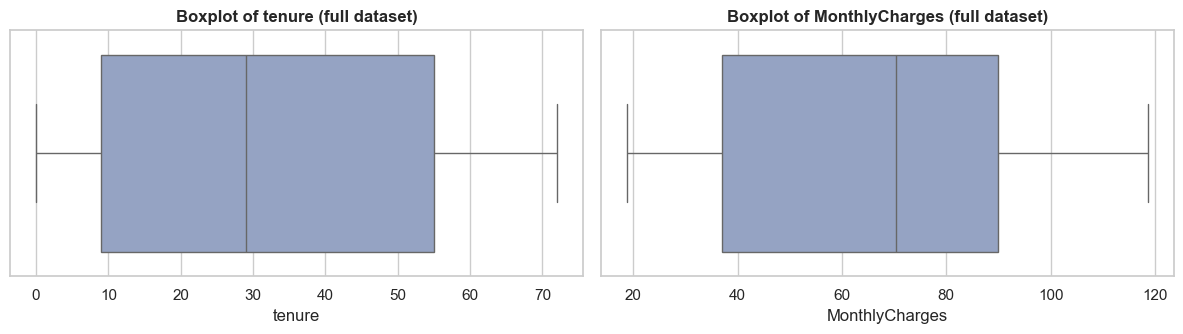

In [14]:
iqr_rows = []
for col in NUMERIC_FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_rows.append({"feature": col, "Q1": q1, "Q3": q3, "lower fence": lower, "upper fence": upper,
                     "min": df[col].min(), "max": df[col].max(),
                     "n outliers": int(((df[col] < lower) | (df[col] > upper)).sum())})
display(pd.DataFrame(iqr_rows).set_index("feature"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(x=df[col], ax=ax, color="#8DA0CB")
    ax.set_title(f"Boxplot of {col} (full dataset)")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

In [15]:
print("Records with tenure == 0:")
display(df[df["tenure"] == 0])

print("MonthlyCharges by InternetService (logical consistency check):")
display(df.groupby("InternetService")["MonthlyCharges"].describe())

Records with tenure == 0:


,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges,Churn
82,Yes,0,No,Yes,DSL,Yes,Yes,Two year,No,73.3500,No
325,Yes,0,Yes,No,DSL,Yes,Yes,Two year,Yes,52.5500,No
1053,Yes,0,No internet service,No internet service,No,No internet service,No internet service,Two year,No,25.3500,No
2017,Yes,0,Yes,Yes,DSL,Yes,No,Two year,No,80.8500,No
2902,Yes,0,Yes,Yes,DSL,No,Yes,Two year,Yes,61.9000,No
3410,Yes,0,Yes,Yes,DSL,Yes,Yes,Two year,No,56.0500,No
4192,Yes,0,No internet service,No internet service,No,No internet service,No internet service,Two year,No,20.2500,No
4441,Yes,0,No internet service,No internet service,No,No internet service,No internet service,Two year,No,19.8500,No


MonthlyCharges by InternetService (logical consistency check):


,count,mean,std,min,25%,50%,75%,max
InternetService,,,,,,,,
DSL,"1,706.0000",58.1244,15.9951,23.4500,47.8500,56.0750,69.7000,93.2500
Fiber optic,"2,172.0000",91.3987,12.7082,67.7500,80.5375,91.6250,101.1125,118.6500
No,"1,052.0000",21.0981,2.1782,18.8000,19.7000,20.1500,20.9000,26.9000


**Findings**

- **No IQR outliers.** Neither numeric feature has values beyond the IQR fences (tenure fences −60 / 124; MonthlyCharges fences −42.15 / 169.05). Both ranges are plausible for a telecom customer base, so **no outlier treatment is applied**. The tree models are insensitive to outliers anyway, and for Logistic Regression standardisation is enough when no extreme values exist.
- **`tenure = 0` (8 customers).**
  - All have a **two-year contract**, all have dependents, and **none churned**.
  - They are most plausibly brand-new sign-ups whose first full month has not yet been counted. That is a legitimate business state, not an error.
  - They are kept. Note, though, that the model can say little about the outcome of brand-new customers, because these customers have not yet had the chance to churn.
- **`MonthlyCharges` is logically consistent with `InternetService`.**
  - No internet: 18.80–26.90 (mean 21.10).
  - DSL: 23.45–93.25 (mean 58.12).
  - Fiber optic: 67.75–118.65 (mean 91.40).
  - Prices rise with the service level and there are no impossible combinations. The strong link also warns of **redundancy between `MonthlyCharges` and `InternetService`** (examined in Section 10).

## 5.7 Data Cleaning Summary

| Check | Result | Action |
|---|---|---|
| Missing values | None (explicit or disguised) | None needed |
| Duplicates | 77 exact duplicate rows (146 rows in groups); 39 identical profiles with conflicting labels | **Kept** — no ID to prove they are errors; consistent with distinct customers sharing low-information profiles |
| Data types | Correct (int, float, text) | None |
| Category validity | All values match expected categories; no typos or whitespace | Assertions keep this enforced |
| Structural values | `No internet service` ⇔ `InternetService = No` | Handled by encoding (Section 8), not imputation |
| Near-zero variance | None (max dominant share 69.9%) | None |
| Outliers | None by IQR | None |
| `tenure = 0` | 8 new two-year customers, none churned | Kept (legitimate) |
| Irrelevant features | No ID or constant columns | None dropped |

The dataset needs **no row removal and no value correction**. All remaining preparation consists of encoding and scaling, done inside the modelling pipeline.

# 6. Train/Test Split

**What:** one stratified split into 80% training and 20% test data, with `random_state = 34`.

**Why stratified:** churners are the minority class (about 27%). Stratification guarantees that the training and test sets have the same churn proportion, so the test set is representative and metric estimates are not distorted by an unlucky split.

**Why 80/20:** with 4,930 rows, 20% gives a test set of roughly 990 customers, including about 260 churners, which is enough for a reasonably stable estimate of recall and precision. The remaining ~3,940 rows give the models as much training data as possible. A separate validation set is not needed because 5-fold cross-validation on the training set plays that role.

**Alternatives considered:** 70/30 (a more stable test estimate but less training data) and a three-way train/validation/test split (wasteful for a dataset of this size when cross-validation is available).

From this point onward, **every notebook up to 08 uses only `X_train` / `y_train`.** The test set is used once, in notebook 09.

In [16]:
X_train, X_test, y_train, y_test = split_train_test(df)   # stratified 80/20, random_state = 34
X, y = df[FEATURES], df[TARGET].map(TARGET_MAP)

split_summary = pd.DataFrame({
    "rows": [len(X), len(X_train), len(X_test)],
    "columns": [X.shape[1], X_train.shape[1], X_test.shape[1]],
    "churners": [y.sum(), y_train.sum(), y_test.sum()],
    "churn rate (%)": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=["full", "train", "test"]).round(2)
display(split_summary)

,rows,columns,churners,churn rate (%)
full,4930,10,1316,26.6900
train,3944,10,1053,26.7000
test,986,10,263,26.6700


In [17]:
# Exact-duplicate overlap between test and training rows (features only)
train_profiles = set(map(tuple, X_train.astype(str).values))
test_rows_seen_in_train = int(sum(tuple(row) in train_profiles for row in X_test.astype(str).values))
print(f"Test rows whose exact feature profile also appears in training: "
      f"{test_rows_seen_in_train} of {len(X_test)} ({test_rows_seen_in_train / len(X_test):.1%})")

# A single CV splitter, reused everywhere so all models see identical folds
CV = get_cv()

# Training DataFrame with the numeric target, used for EDA
train_df = X_train.assign(Churn=y_train)
OVERALL_CHURN = y_train.mean()
print(f"Training churn rate (reference line in EDA plots): {OVERALL_CHURN:.2%}")

Test rows whose exact feature profile also appears in training: 34 of 986 (3.4%)
Training churn rate (reference line in EDA plots): 26.70%


**Result**

- **Training set:** 3,944 customers (1,053 churners, 26.70%).
- **Test set:** 986 customers (263 churners, 26.67%).
- Stratification reproduced the overall churn rate (26.69%) almost exactly in both sets.

**Duplicate overlap.** 34 of 986 test customers (3.4%) have a feature profile that also appears in the training set. Because the duplicates are treated as distinct customers (Section 5.2), this reflects the real population rather than leakage. In the worst case, where some are double exports, it affects at most 3.4% of test rows and would bias test metrics only marginally.

## 6.1 Exporting the Cleaned and Split Datasets

**Why:** for transparency and convenient reuse, the cleaned data and this exact split are also written to `data/processed/`. The files are produced by `src.data_preprocessing.export_processed_datasets`, which calls the **same** `split_train_test` function used above and in every model notebook. The split is not drawn again.

| File | Content |
|---|---|
| `data_cleaned.csv` | All 4,930 observations after the Section 5.7 cleaning decisions (no row removed, no value changed) |
| `data_train.csv` | The 3,944 training customers, in `split_train_test` order |
| `data_test.csv` | The 986 test customers, in `split_train_test` order |
| `split_metadata.json` | Split configuration (`test_size = 0.20`, stratified on `Churn`, `random_state = 34`), row counts and SHA-256 hashes |

**Design choices**
- **`row_id` column** = the row's position in the raw CSV. Because 77 exact duplicate rows are kept (Section 5.2), identical rows can legitimately appear in both sets; only an identifier can prove that no *observation* is in both.
- **Row order is preserved.** The shared 5-fold splitter assigns folds by position, so the exported training file reproduces the project's CV folds exactly.
- **Not model-ready.** Categorical columns keep their original text values, `tenure` is not log-transformed and nothing is scaled. Encoding and scaling are learned inside the pipeline on training folds only.
- `data_test.csv` is provided for reproducibility of the single final evaluation (notebook 09). It must not be used for any modelling decision.

In [18]:
from src.data_preprocessing import ROW_ID, export_processed_datasets, load_processed, verify_processed_datasets

export_paths = export_processed_datasets(PROJECT_ROOT)
export_report = verify_processed_datasets(PROJECT_ROOT)   # raises AssertionError if any integrity check fails
display(export_report.round(2))

# Duplicate rows split across the two files are different observations (different row_id)
train_rows = set(map(tuple, load_processed("train", PROJECT_ROOT).drop(columns=ROW_ID).astype(str).values))
test_export = load_processed("test", PROJECT_ROOT).drop(columns=ROW_ID).astype(str).values
print(f"Test rows identical (features and label) to a training row: {sum(tuple(r) in train_rows for r in test_export)}")
print("Files written:", [p.relative_to(PROJECT_ROOT).as_posix() for p in export_paths.values()])
print("Integrity checks passed: files exist and load; row counts, columns, dtypes and missing values are correct; "
      "train and test share no row_id and together cover every cleaned row; the cleaned file equals the raw data; "
      "train/test membership and row order equal split_train_test(df); split configuration recorded.")

,rows,columns,share of cleaned rows (%),Churn = Yes,Churn = No,churn rate (%),exact duplicate rows (excl. row_id),missing values
file,,,,,,,,
data_cleaned.csv,4930,12,100.0000,1316,3614,26.6900,77,0
data_train.csv,3944,12,80.0000,1053,2891,26.7000,47,0
data_test.csv,986,12,20.0000,263,723,26.6700,6,0


Test rows identical (features and label) to a training row: 26
Files written: ['data/processed/data_cleaned.csv', 'data/processed/data_train.csv', 'data/processed/data_test.csv']
Integrity checks passed: files exist and load; row counts, columns, dtypes and missing values are correct; train and test share no row_id and together cover every cleaned row; the cleaned file equals the raw data; train/test membership and row order equal split_train_test(df); split configuration recorded.


**Result.** The integrity checks passed. The cleaned file has 4,930 rows, and the training and test files have 3,944 (80%) and 986 (20%) rows, with churn rates of 26.70% and 26.67%. No missing values were introduced. The exact duplicates are distributed across the files as the split dictates: some sit within the training file, some within the test file, and the remaining identical rows straddle the two as distinct observations with different `row_id`s. The original raw file is only read, never written.

# 7. Exploratory Data Analysis (Training Set Only)

All analyses in this section use the **training set** (n ≈ 3,944). Observations are descriptive associations; they do not establish that any feature *causes* churn.

## 7.1 Univariate Analysis

### 7.1.1 Target Distribution

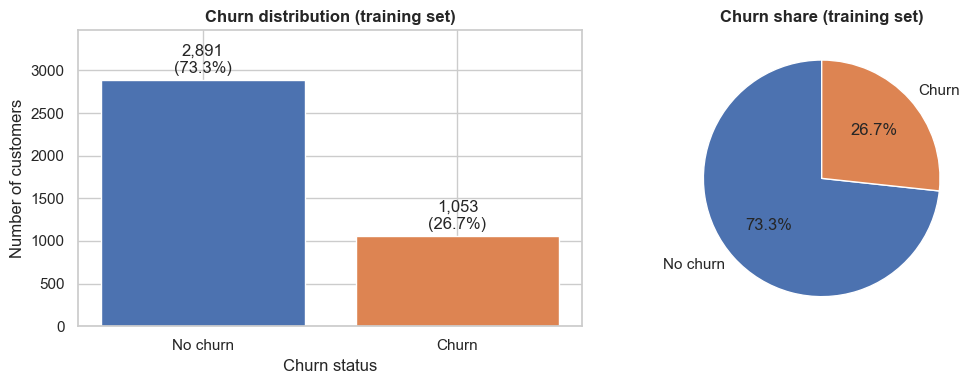

In [19]:
counts = train_df["Churn"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar([CHURN_LABELS[i] for i in counts.index], counts.values, color=[PALETTE[i] for i in counts.index])
axes[0].bar_label(bars, labels=[f"{v:,}\n({v / counts.sum():.1%})" for v in counts.values], padding=3)
axes[0].set_title("Churn distribution (training set)")
axes[0].set_xlabel("Churn status")
axes[0].set_ylabel("Number of customers")
axes[0].set_ylim(0, counts.max() * 1.2)

axes[1].pie(counts.values, labels=[CHURN_LABELS[i] for i in counts.index], autopct="%1.1f%%",
            colors=[PALETTE[i] for i in counts.index], startangle=90, wedgeprops={"edgecolor": "white"})
axes[1].set_title("Churn share (training set)")
plt.tight_layout()
save_figure(fig, "00_target_distribution")
plt.show()

**Interpretation:** the training set reproduces the overall class balance. 1,053 customers (26.7%) churned and 2,891 (73.3%) stayed. A churn rate of about one in four is high enough that churn is a material business problem, and imbalanced enough that metrics focused on the churn class (recall, precision, PR-AUC) must be used instead of accuracy.

### 7.1.2 Numerical Feature Distributions

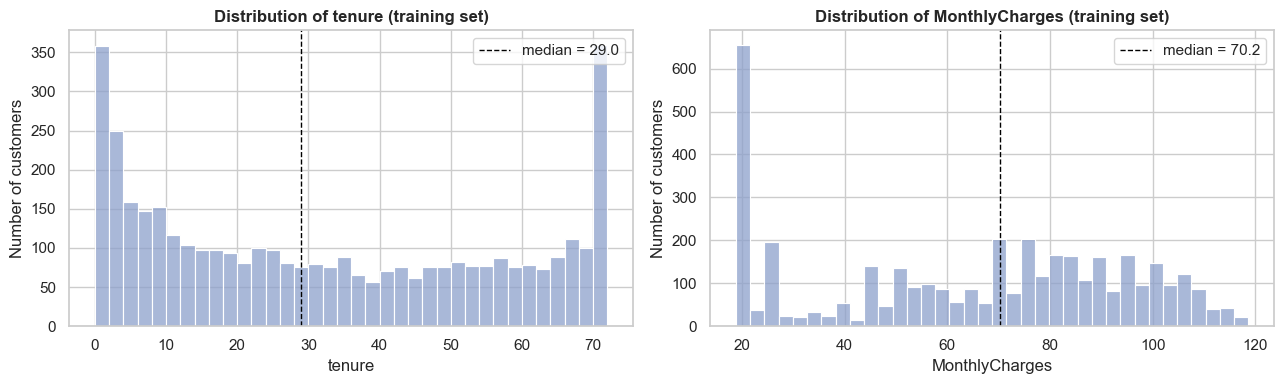

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.histplot(train_df[col], bins=36, ax=ax, color="#8DA0CB", edgecolor="white")
    ax.axvline(train_df[col].median(), color="black", linestyle="--", linewidth=1,
               label=f"median = {train_df[col].median():.1f}")
    ax.set_title(f"Distribution of {col} (training set)")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretation**

- **`tenure`** is far from normal. There is a large mass of very new customers (the first few months) and a pronounced spike at 72 months, the maximum, suggesting either a loyal long-standing cohort or a cap on recorded tenure. The median is 29 months.
- **`MonthlyCharges`** is **multimodal**. A tall, narrow peak near 20 corresponds to customers without internet service (Section 5.6), and a broad spread from about 45 to 110 corresponds to DSL and fiber customers. The distribution is a mixture of service-type sub-populations rather than one homogeneous group.

These shapes are why non-parametric tests are used in Section 10. They also explain why tree-based models, which can split at any value, may capture threshold effects that a linear model cannot.

### 7.1.3 Categorical Feature Distributions

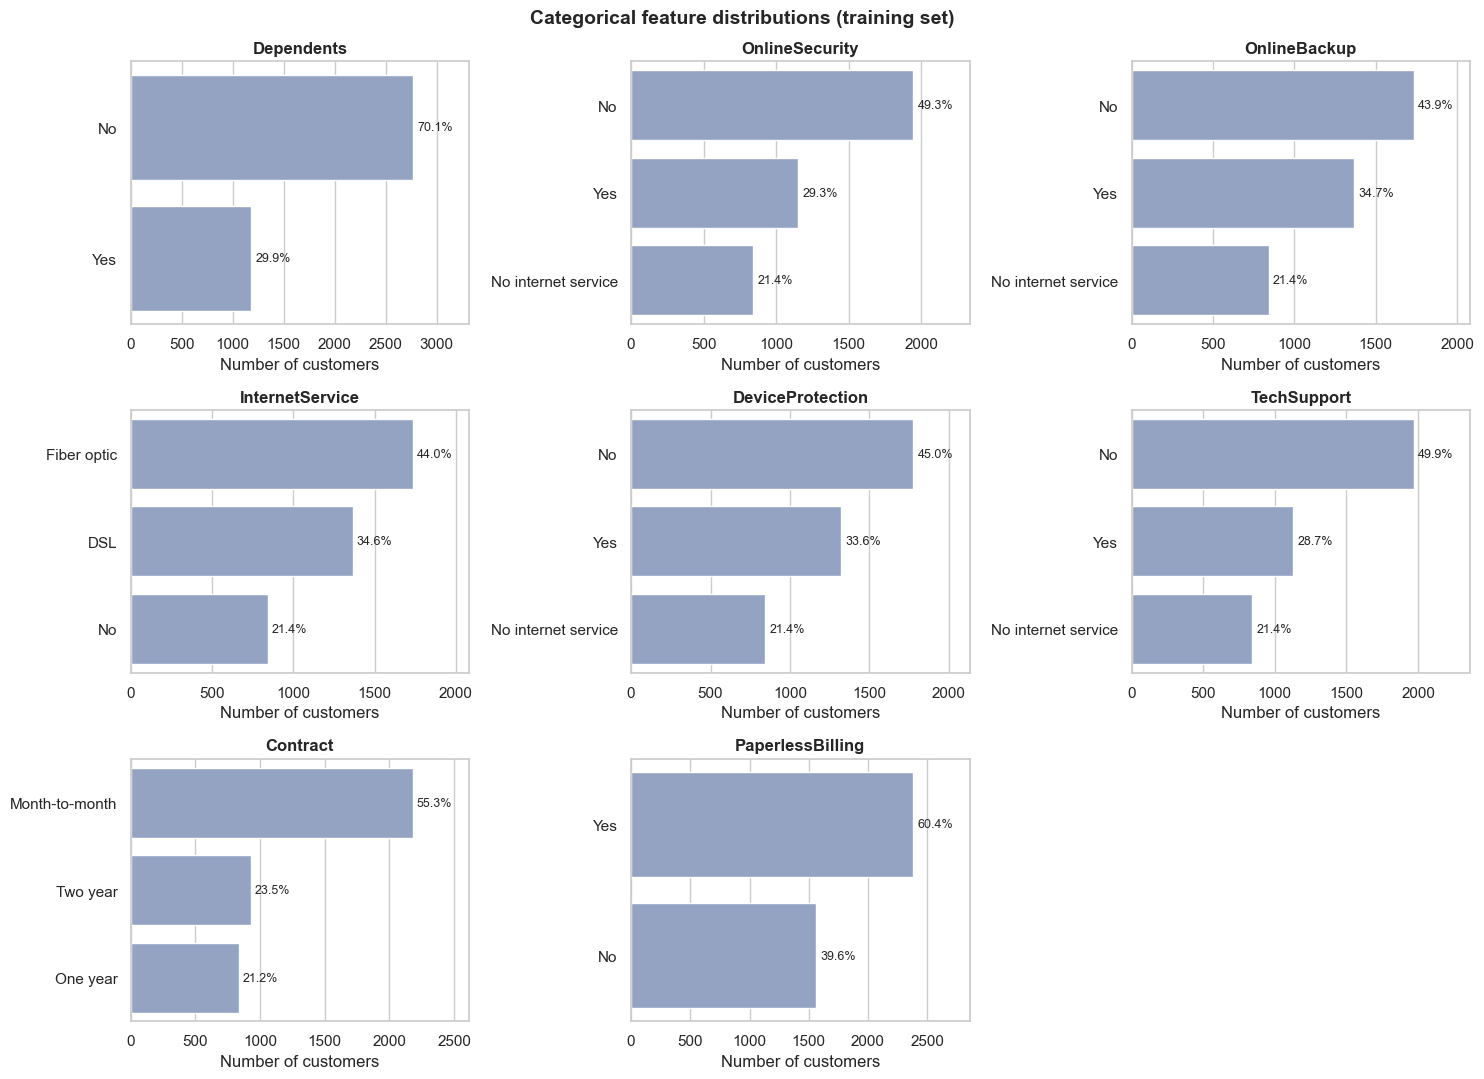

In [21]:
CATEGORICAL_FEATURES = [c for c in X_train.columns if c not in NUMERIC_FEATURES]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), CATEGORICAL_FEATURES):
    order = train_df[col].value_counts().index
    sns.countplot(data=train_df, y=col, order=order, ax=ax, color="#8DA0CB")
    total = len(train_df)
    for p in ax.patches:
        ax.annotate(f"{p.get_width() / total:.1%}", (p.get_width(), p.get_y() + p.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_title(col)
    ax.set_xlabel("Number of customers")
    ax.set_ylabel("")
    ax.set_xlim(0, train_df[col].value_counts().max() * 1.2)
for ax in axes.ravel()[len(CATEGORICAL_FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Categorical feature distributions (training set)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation**

- **Contract:** most customers (55.3%) are on **month-to-month** contracts, the least committed arrangement.
- **InternetService:** fiber optic is the most common service (44.0%), followed by DSL (34.6%); 21.4% have no internet service.
- **Add-ons:** for each one, "No" is the largest group (43.9–49.9%), "Yes" is 28.7–34.7%, and the remaining 21.4% are customers without internet.
- **Dependents:** 70.1% of customers have no dependents.
- **PaperlessBilling:** 60.4% use paperless billing.

Every category has hundreds of customers, so no category is too rare to estimate reliably.

## 7.2 Bivariate Analysis (Features vs Churn)

### 7.2.1 Numerical Features vs Churn

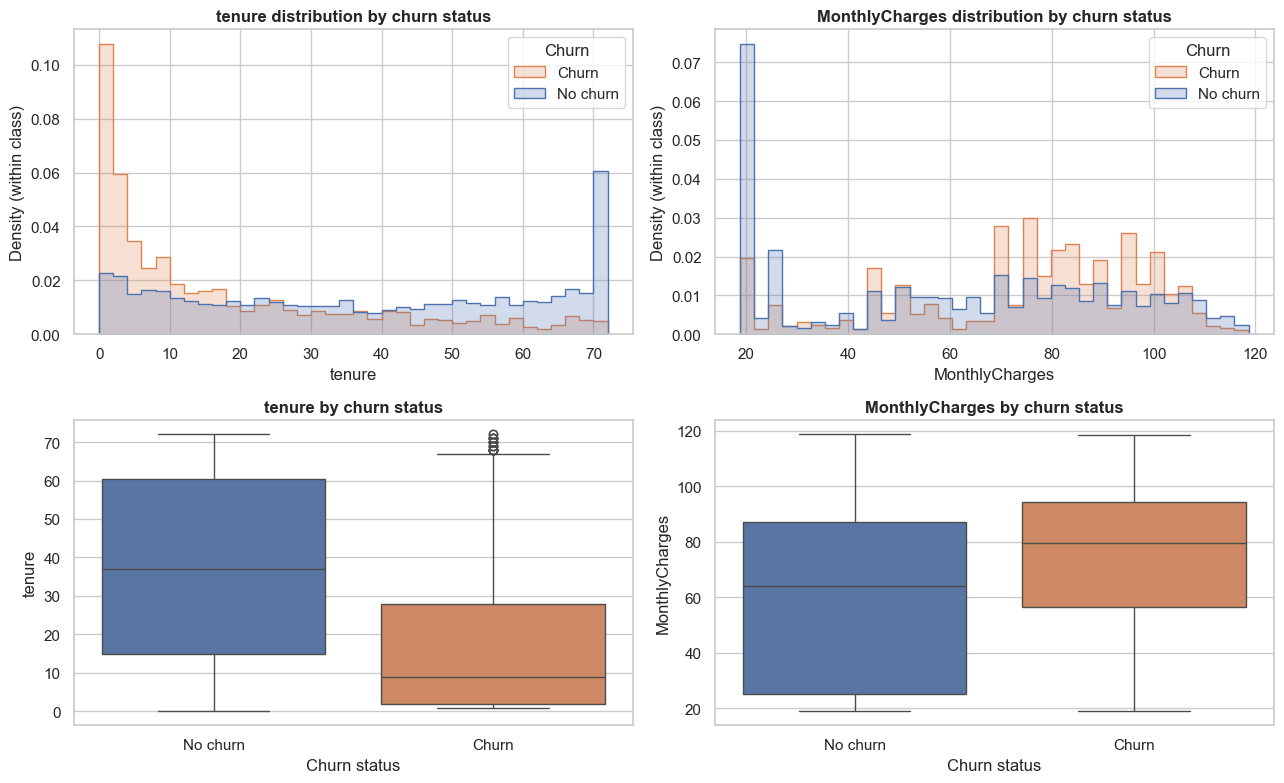

tenure         MonthlyCharges        
          median    mean         median    mean
Churn                                          
No churn 37.0000 37.5054        64.1500 61.1134
Churn     9.0000 17.5935        79.5500 74.3208

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, col in enumerate(NUMERIC_FEATURES):
    sns.histplot(data=train_df, x=col, hue="Churn", bins=36, stat="density", common_norm=False,
                 element="step", palette=PALETTE, ax=axes[0, i])
    axes[0, i].set_title(f"{col} distribution by churn status")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Density (within class)")
    axes[0, i].legend(title="Churn", labels=["Churn", "No churn"])

    sns.boxplot(data=train_df, x="Churn", y=col, hue="Churn", palette=PALETTE, legend=False, ax=axes[1, i])
    axes[1, i].set_xticks([0, 1], [CHURN_LABELS[0], CHURN_LABELS[1]])
    axes[1, i].set_title(f"{col} by churn status")
    axes[1, i].set_xlabel("Churn status")
    axes[1, i].set_ylabel(col)
plt.tight_layout()
plt.show()

display(train_df.groupby("Churn")[NUMERIC_FEATURES].agg(["median", "mean"]).rename(index=CHURN_LABELS))

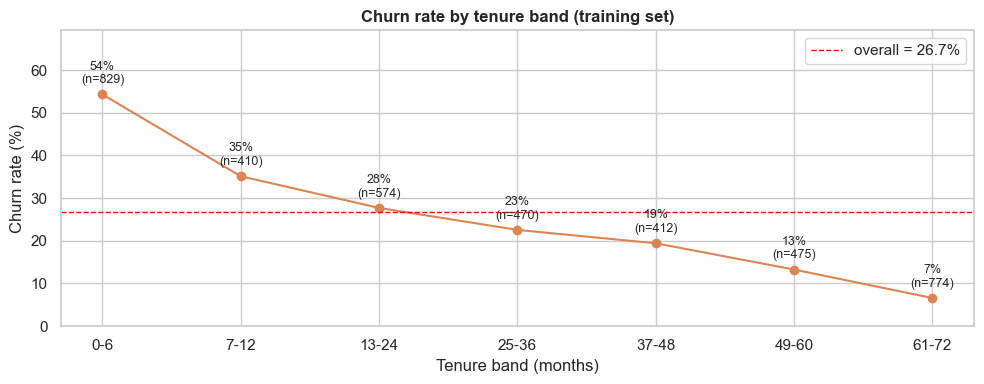

In [23]:
# Churn rate across tenure bands
tenure_bands = pd.cut(train_df["tenure"], bins=[-1, 6, 12, 24, 36, 48, 60, 72],
                      labels=["0-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
tenure_rate = train_df.groupby(tenure_bands, observed=True)["Churn"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tenure_rate.index.astype(str), tenure_rate["mean"] * 100, marker="o", color=PALETTE[1])
for x, (rate, n) in enumerate(zip(tenure_rate["mean"], tenure_rate["size"])):
    ax.annotate(f"{rate:.0%}\n(n={n})", (x, rate * 100), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=9)
ax.axhline(OVERALL_CHURN * 100, color="red", linestyle="--", linewidth=1, label=f"overall = {OVERALL_CHURN:.1%}")
ax.set_title("Churn rate by tenure band (training set)")
ax.set_xlabel("Tenure band (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, tenure_rate["mean"].max() * 100 + 15)
ax.legend()
plt.tight_layout()
save_figure(fig, "00_churn_by_tenure")
plt.show()

**Interpretation**

- **Tenure is the clearest separator.**
  - Churners have a median tenure of **9 months** vs **37 months** for non-churners.
  - The churn-rate curve falls steadily: **54% in the first 6 months**, 35% at 7–12, 28% at 13–24, and **7% after 5 years** (61–72 months).
  - Churn is concentrated early in the customer relationship.
- **MonthlyCharges is higher for churners** (median 79.55 vs 64.15). The density plot shows that low-charge customers (around 20, i.e. no internet service) rarely churn, while churners are concentrated in the 70–105 range.
- **Caveat:** these are associations. Long-tenure customers may churn less partly because customers who were going to leave have *already* left (survivorship), not because tenure itself creates loyalty. The higher churn among higher-paying customers may reflect the service type (fiber), not the price alone.

### 7.2.2 Categorical Features vs Churn

Each bar shows the churn rate within a category; the red dashed line is the overall training churn rate. Sample sizes are shown so that small groups are not over-interpreted.

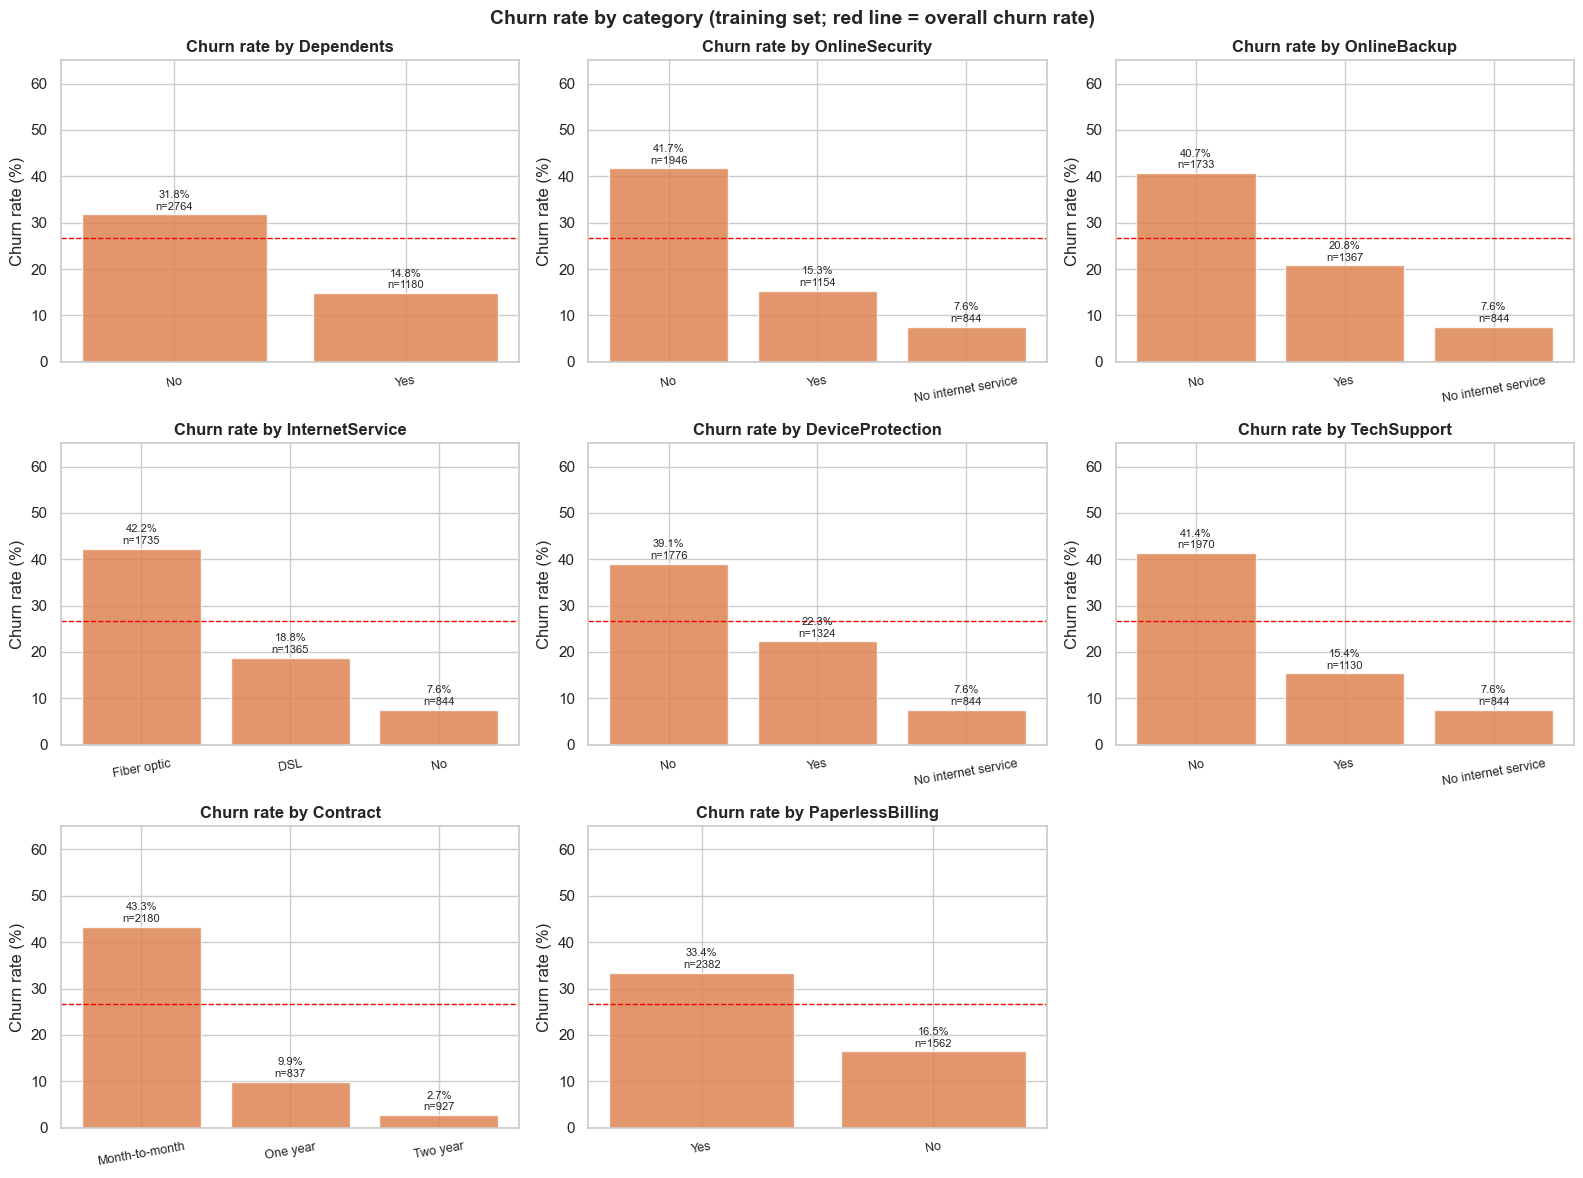

In [24]:
def churn_rate_table(data: pd.DataFrame, col: str) -> pd.DataFrame:
    # Churn rate and size of each category of `col`.
    return (data.groupby(col, observed=True)["Churn"].agg(churn_rate="mean", n="size")
            .sort_values("churn_rate", ascending=False))


fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), CATEGORICAL_FEATURES):
    tbl = churn_rate_table(train_df, col)
    bars = ax.bar(tbl.index.astype(str), tbl["churn_rate"] * 100, color="#DD8452", alpha=0.85)
    ax.bar_label(bars, labels=[f"{r:.1%}\nn={n}" for r, n in zip(tbl["churn_rate"], tbl["n"])],
                 padding=2, fontsize=8)
    ax.axhline(OVERALL_CHURN * 100, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, 65)
    ax.tick_params(axis="x", labelsize=9, rotation=10)
for ax in axes.ravel()[len(CATEGORICAL_FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Churn rate by category (training set; red line = overall churn rate)", fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure(fig, "00_churn_rate_by_category")
plt.show()

**Interpretation** (training churn rate = 26.7%)

- **Contract** shows the largest contrast: **43.3%** churn on month-to-month vs **9.9%** on one-year and **2.7%** on two-year contracts.
- **InternetService:** fiber-optic customers churn at **42.2%**, more than twice the DSL rate (18.8%). Customers without internet churn at only 7.6%.
- **Add-on services** all show the same pattern. Customers *without* the add-on churn much more than customers with it:
  - OnlineSecurity: 41.7% vs 15.3%;
  - TechSupport: 41.4% vs 15.4%;
  - OnlineBackup: 40.7% vs 20.8%;
  - DeviceProtection: 39.1% vs 22.3%.
  - The protective association is strongest for **OnlineSecurity** and **TechSupport**.
- **PaperlessBilling:** 33.4% churn with paperless billing vs 16.5% without.
- **Dependents:** customers without dependents churn at 31.8% vs 14.8% for customers with dependents.

These differences are large and rest on hundreds of customers per group, so they're unlikely to be chance (formal tests in Section 10). They are still not causal. For example, customers who buy technical support may differ in engagement or technical confidence, and simply adding TechSupport to a customer's plan would not necessarily reproduce the lower churn rate.

## 7.3 Feature Relationships and Potential Interactions

Relationships *between* features matter for two reasons: strongly related features can make model coefficients hard to interpret (multicollinearity), and combinations of features may reveal risk segments that single-feature analysis misses.

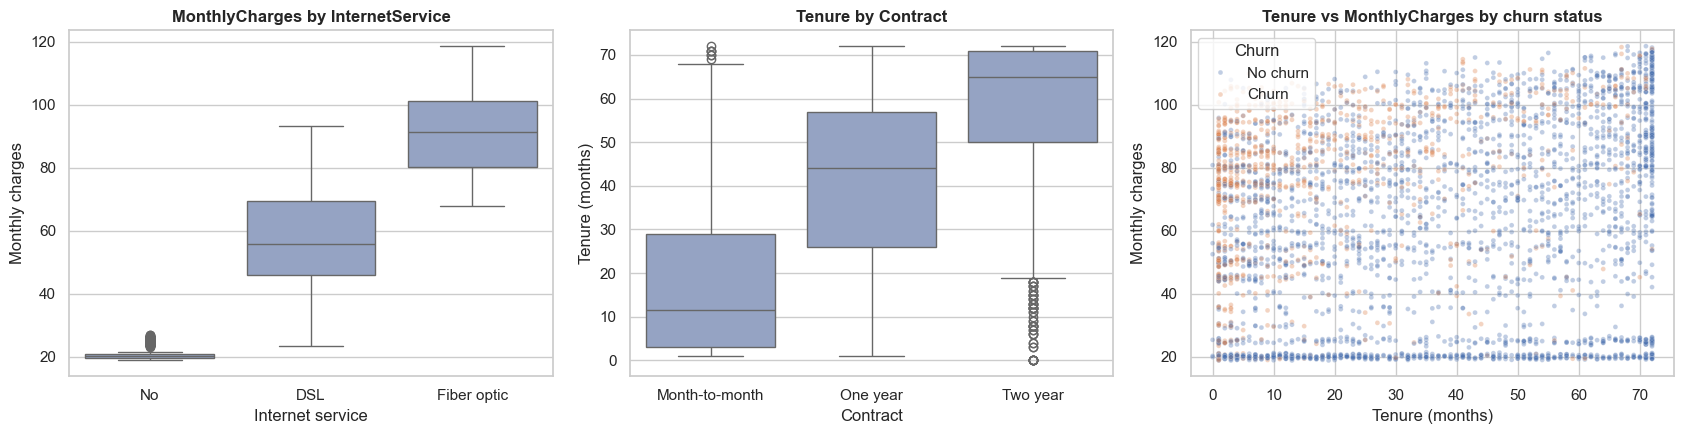

Spearman correlation tenure vs MonthlyCharges: rho = 0.257 (p = 1.5e-60)


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(data=train_df, x="InternetService", y="MonthlyCharges", order=["No", "DSL", "Fiber optic"],
            color="#8DA0CB", ax=axes[0])
axes[0].set_title("MonthlyCharges by InternetService")
axes[0].set_xlabel("Internet service")
axes[0].set_ylabel("Monthly charges")

sns.boxplot(data=train_df, x="Contract", y="tenure", order=["Month-to-month", "One year", "Two year"],
            color="#8DA0CB", ax=axes[1])
axes[1].set_title("Tenure by Contract")
axes[1].set_xlabel("Contract")
axes[1].set_ylabel("Tenure (months)")

sns.scatterplot(data=train_df, x="tenure", y="MonthlyCharges", hue="Churn", palette=PALETTE, alpha=0.35,
                s=12, ax=axes[2])
axes[2].set_title("Tenure vs MonthlyCharges by churn status")
axes[2].set_xlabel("Tenure (months)")
axes[2].set_ylabel("Monthly charges")
handles, _ = axes[2].get_legend_handles_labels()
axes[2].legend(handles, ["No churn", "Churn"], title="Churn")
plt.tight_layout()
plt.show()

rho, p_rho = stats.spearmanr(train_df["tenure"], train_df["MonthlyCharges"])
print(f"Spearman correlation tenure vs MonthlyCharges: rho = {rho:.3f} (p = {p_rho:.2g})")

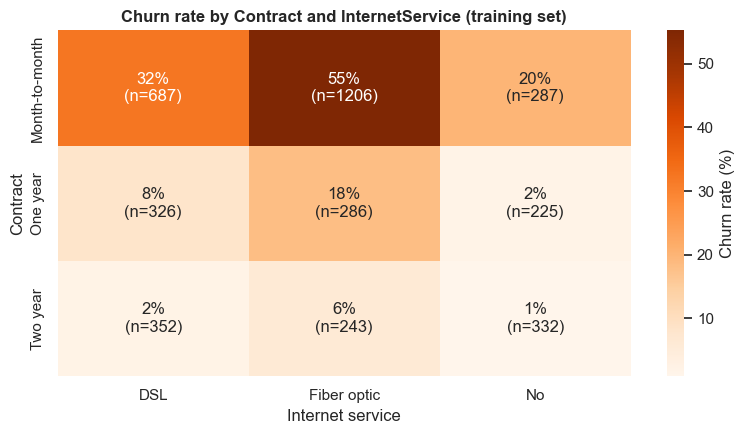

In [26]:
# Interaction: churn rate for each Contract x InternetService combination
pivot_rate = train_df.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="mean")
pivot_n = train_df.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="size")
annot = pivot_rate.map(lambda v: f"{v:.0%}") + "\n(n=" + pivot_n.astype(str) + ")"

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot_rate * 100, annot=annot, fmt="", cmap="Oranges", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate by Contract and InternetService (training set)")
ax.set_xlabel("Internet service")
ax.set_ylabel("Contract")
plt.tight_layout()
save_figure(fig, "00_contract_internet_heatmap")
plt.show()

**Interpretation**

- **MonthlyCharges is largely determined by InternetService.** The three boxes barely overlap. This is a potential source of **multicollinearity** for Logistic Regression and is quantified in Sections 8.4 and 10.4.
- **Tenure is strongly related to Contract.** Customers on longer contracts have much longer tenure. Contract and tenure therefore partly carry the same information ("committed, established customer"), so their individual coefficients will share credit.
- **Tenure vs MonthlyCharges** shows a weak positive monotonic relationship (Spearman ρ = 0.257). Churners (orange) cluster at **low tenure and high monthly charges**.
- **Interaction:** **month-to-month + fiber optic** has the highest churn rate of any segment, **55%**, among 1,206 training customers (31% of the training set). By comparison, month-to-month + DSL is 32%, and any two-year contract is at most 6%. The fiber effect is much stronger among month-to-month customers, suggesting that risk factors compound. Tree models can capture such interactions directly; Logistic Regression assumes the effects add up on the log-odds scale.

## 7.4 EDA Summary

| Finding | Evidence (training set) | Implication |
|---|---|---|
| Churn concentrates among new customers | 54% churn in the first 6 months vs 7% after 5 years | `tenure` is likely the most important predictor; its non-linear shape motivates Section 9 |
| Commitment is protective | 43.3% churn month-to-month vs 2.7% two-year | `Contract` encoding matters; examined in Section 8.3 |
| Fiber-optic customers churn most | 42.2% vs 18.8% DSL | Possibly price or service-experience related; not provable from this data |
| Add-on services associated with lower churn | e.g. OnlineSecurity 15.3% vs 41.7% without | The binary "has the add-on" information is what matters |
| Highest-risk segment | Month-to-month + fiber: 55% churn (n = 1,206) | A natural priority group for retention |
| Redundancy | MonthlyCharges ↔ InternetService; tenure ↔ Contract | Check multicollinearity; interpret coefficients carefully |

All of these are **associations observed in historical data**. They identify *who* is at risk, not *why*.

# 8. Data Preprocessing

## 8.1 Encoding Strategy

| Feature group | Columns | Transformation | Reason |
|---|---|---|---|
| Binary | `Dependents`, `PaperlessBilling` | `OneHotEncoder` with explicit categories `[No, Yes]` and `drop='first'` → a single 0/1 column (`*_Yes`). | Truly binary. Using a standard encoder with explicit categories makes the pipeline **raise an error** on unexpected values instead of silently producing missing values. |
| Add-on services | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | Custom, stateless `FunctionTransformer`: **Yes → 1, otherwise → 0**; raises an error on any value outside the three known categories. | Section 5.4 proved that `No internet service` is fully determined by `InternetService = No`. Keeping it as a separate level would create four columns identical to `InternetService_No` (perfect redundancy). The binary indicator keeps the meaningful information ("does the customer have this service?") and lets `InternetService` carry the "no internet" information. |
| Internet service | `InternetService` | `OneHotEncoder`, categories `[DSL, Fiber optic, No]`, `drop='first'` (reference = DSL). | Nominal variable: there is no meaningful numeric distance between DSL, Fiber optic and No. A reference category keeps Logistic Regression coefficients readable ("relative to DSL"). |
| Contract | `Contract` | **Investigated in Section 8.3:** ordinal (0/1/2) vs one-hot. | The categories have a natural order of commitment length, but ordinal encoding also imposes *equal spacing*, which must be checked. |
| Numerical | `tenure`, `MonthlyCharges` | `StandardScaler` (a log transformation of `tenure` is evaluated in Section 9). | Logistic Regression is regularised, so the penalty depends on feature scale; standardisation puts both features on a comparable scale. Scaling does not affect tree-based models, so a single shared preprocessor is used for all models. |
| Missing values | — | **No imputer.** | There are no missing values (Section 5.1). An imputer would silently hide unexpected nulls in future data; without one the pipeline fails loudly, which is the safer behaviour. |

All transformations are wrapped in a `ColumnTransformer` inside a `Pipeline`, so any learned parameter (e.g. the scaler's mean and standard deviation) is estimated **only on the training data of each fold**.

In [27]:
# The encoders and the preprocessing factory are defined once in src/data_preprocessing.py.
# Their documentation is printed here so that the notebook remains self-explanatory.
print(encode_addons.__doc__)
print(make_preprocessor.__doc__)
print(build_pipeline.__doc__)

Add-on services: Yes -> 1, No / No internet service -> 0. Raises on unexpected values.
Build the ColumnTransformer for a feature subset and encoding variant.

contract : "onehot" (reference Month-to-month) or "ordinal" (0/1/2)
addons   : "binary" (Yes=1, otherwise 0) or "onehot3" (keeps the structural 'No internet service' level)
tenure   : "raw" (scaled months), "log" (scaled log1p months) or "group" (one-hot life-cycle bands)
extra_numeric / extra_binary : engineered columns produced by feature_engineering.engineer_features

Preprocessing (+ optional feature engineering / resampling) + model in one pipeline.

engineer : prepend the stateless candidate-feature step (feature_engineering.engineer_features)
sampler  : an imbalanced-learn sampler; it is placed first and is applied ONLY during fit,
           i.e. only to the training part of each fold - never to validation or test data.



## 8.2 Inspecting the Transformed Training Matrix

To verify the encoders behave as intended, the default preprocessor (one-hot Contract) is fitted on the training set **for inspection only** and its output is checked.

In [28]:
prep_check = make_preprocessor().set_output(transform="pandas").fit(X_train)
Xt_check = prep_check.transform(X_train)

print(f"Encoded feature count: {Xt_check.shape[1]}")
print("Encoded feature names:", list(Xt_check.columns))
display(Xt_check.head())

# Verification checks
binary_cols = [c for c in Xt_check.columns if c not in NUMERIC_FEATURES]
assert Xt_check[binary_cols].isin([0, 1]).all().all(), "Non-binary values in encoded categorical columns"
for col in ADDON_FEATURES:
    assert Xt_check[col].sum() == (X_train[col] == "Yes").sum(), f"Add-on encoding mismatch for {col}"
assert Xt_check["InternetService_No"].sum() == (X_train["InternetService"] == "No").sum()
print("\nScaled numeric columns on the training data (mean ~ 0, std ~ 1):")
display(Xt_check[NUMERIC_FEATURES].agg(["mean", "std"]).round(3))
print("All encoding checks passed.")

Encoded feature count: 12
Encoded feature names: ['Dependents_Yes', 'PaperlessBilling_Yes', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'tenure', 'MonthlyCharges']


,Dependents_Yes,PaperlessBilling_Yes,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,tenure,MonthlyCharges
2878,0.0000,1.0000,1,1,0,0,1.0000,0.0000,0.0000,0.0000,0.9300,1.0736
2607,1.0000,1.0000,0,0,0,0,1.0000,0.0000,0.0000,0.0000,-0.3746,0.6390
1060,1.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,0.0000,-0.9862,-0.6684
3617,0.0000,1.0000,0,0,0,0,0.0000,0.0000,1.0000,0.0000,1.5415,-0.6483
2533,0.0000,1.0000,0,0,0,0,1.0000,0.0000,0.0000,0.0000,-1.2716,0.1659



Scaled numeric columns on the training data (mean ~ 0, std ~ 1):


,tenure,MonthlyCharges
mean,0.0000,-0.0000
std,1.0000,1.0000


All encoding checks passed.


## 8.3 Contract: Ordinal vs One-Hot Encoding

`Contract` has a natural ordering by commitment length (Month-to-month < One year < Two year). However, ordinal encoding as 0/1/2 makes a stronger assumption than "ordered": for Logistic Regression it forces the change in **log-odds of churn** from Month-to-month to One year to equal the change from One year to Two year. One-hot encoding lets each step take its own value at the cost of one extra parameter.

The decision is based on four criteria:
1. **Business meaning** — the order is real (longer commitment), so an ordinal reading is plausible.
2. **Statistical evidence** — are the empirical log-odds steps roughly equal? (computed below on the training set)
3. **Cross-validation performance** — compared in Section 8.4 together with the other encoding variants.
4. **Interpretability** — ordinal gives one coefficient ("per step of commitment"); one-hot gives a coefficient per contract type relative to Month-to-month.

,churners,n,churn_rate,log_odds,se,step_from_previous
Contract,,,,,,
Month-to-month,945,2180,0.4330,-0.2680,0.0430,NaN
One year,83,837,0.0990,-2.2070,0.1160,-1.9390
Two year,25,927,0.0270,-3.5860,0.2030,-1.3790


Step Month-to-month -> One year: -1.939 | Step One year -> Two year: -1.379
Difference between steps = 0.560 (SE 0.311), z = 1.80, p = 0.072


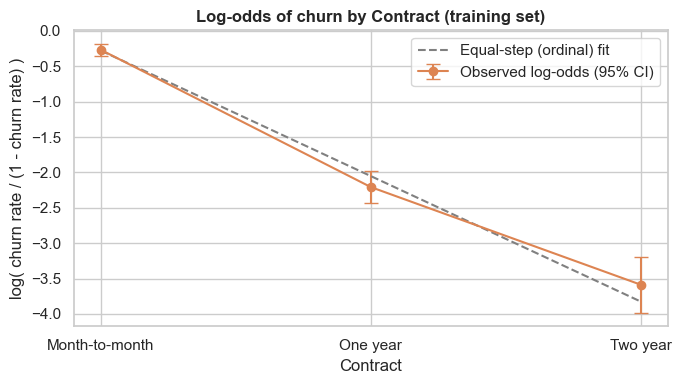

In [29]:
contract_stats = train_df.groupby("Contract")["Churn"].agg(churners="sum", n="size").loc[CATEGORY_ORDER["Contract"]]
contract_stats["churn_rate"] = contract_stats["churners"] / contract_stats["n"]
contract_stats["log_odds"] = np.log(contract_stats["churn_rate"] / (1 - contract_stats["churn_rate"]))
# Standard error of a log-odds estimate: sqrt(1/a + 1/b)
contract_stats["se"] = np.sqrt(1 / contract_stats["churners"] + 1 / (contract_stats["n"] - contract_stats["churners"]))
contract_stats["step_from_previous"] = contract_stats["log_odds"].diff()
display(contract_stats.round(3))

# Test of equal spacing: second difference of log-odds = (LO_2yr - LO_1yr) - (LO_1yr - LO_m2m)
lo, se = contract_stats["log_odds"].to_numpy(), contract_stats["se"].to_numpy()
second_diff = lo[2] - 2 * lo[1] + lo[0]
se_second_diff = np.sqrt(se[2] ** 2 + 4 * se[1] ** 2 + se[0] ** 2)   # independent groups
z_equal = second_diff / se_second_diff
p_equal = 2 * stats.norm.sf(abs(z_equal))
print(f"Step Month-to-month -> One year: {lo[1] - lo[0]:.3f} | Step One year -> Two year: {lo[2] - lo[1]:.3f}")
print(f"Difference between steps = {second_diff:.3f} (SE {se_second_diff:.3f}), z = {z_equal:.2f}, p = {p_equal:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(range(3), contract_stats["log_odds"], yerr=1.96 * contract_stats["se"], marker="o", capsize=5,
            color=PALETTE[1], label="Observed log-odds (95% CI)")
# Best equally spaced (linear) fit, weighted by inverse variance
w = 1 / contract_stats["se"] ** 2
coef = np.polyfit(range(3), contract_stats["log_odds"], 1, w=np.sqrt(w))
ax.plot(range(3), np.polyval(coef, range(3)), linestyle="--", color="gray", label="Equal-step (ordinal) fit")
ax.set_xticks(range(3), CATEGORY_ORDER["Contract"])
ax.set_title("Log-odds of churn by Contract (training set)")
ax.set_xlabel("Contract")
ax.set_ylabel("log( churn rate / (1 - churn rate) )")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation**

- **Observed log-odds** (training set): −0.268 (month-to-month), −2.207 (one year), −3.586 (two year).
- **The two steps are different in size:** −1.94 for the first step and −1.38 for the second. Ordinal encoding would force them to be equal.
- **The difference is only borderline significant:** 0.56 (SE 0.311), z = 1.80, p = 0.072. With only 25 churners on two-year contracts, the two-year estimate is imprecise.
- **Conclusion:** the evidence *suggests* unequal spacing but does not prove it. Statistics alone don't settle the question; Section 8.4 adds the cross-validation comparison.

## 8.4 Comparing Encoding Variants with Cross-Validation

Three preprocessing variants are compared with default-configuration models using 5-fold stratified CV on the training set. The primary score is **PR-AUC (average precision)**, which measures how well churners are ranked above non-churners and is independent of the classification threshold; ROC-AUC is shown as a secondary measure.

| Variant | Add-ons | Contract | Extra feature |
|---|---|---|---|
| A | binary | one-hot | — |
| B | binary | ordinal | — |
| C | 3-level one-hot (keeps "No internet service") | one-hot | — |

In [30]:
BASE_MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),  # explained in notebook 04
}

ENCODING_VARIANTS = {
    "A: binary add-ons, one-hot Contract": dict(contract="onehot", addons="binary"),
    "B: binary add-ons, ordinal Contract": dict(contract="ordinal", addons="binary"),
    "C: 3-level add-ons, one-hot Contract": dict(contract="onehot", addons="onehot3"),
}



rows = []
for variant, kwargs in ENCODING_VARIANTS.items():
    for model_name, model in BASE_MODELS.items():
        res = cv_scores(build_pipeline(model, **kwargs), X_train, y_train,
                        scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
        rows.append({"variant": variant, "model": model_name,
                     "PR-AUC mean": res["test_pr_auc"].mean(), "PR-AUC std": res["test_pr_auc"].std(),
                     "ROC-AUC mean": res["test_roc_auc"].mean(), "ROC-AUC std": res["test_roc_auc"].std()})
encoding_results = pd.DataFrame(rows)

display(encoding_results.pivot(index="variant", columns="model", values="PR-AUC mean").round(4)
        .style.set_caption("CV PR-AUC (mean of 5 folds)"))
display(encoding_results.pivot(index="variant", columns="model", values="PR-AUC std").round(4)
        .style.set_caption("CV PR-AUC (standard deviation across folds)"))
display(encoding_results.pivot(index="variant", columns="model", values="ROC-AUC mean").round(4)
        .style.set_caption("CV ROC-AUC (mean of 5 folds)"))

model,Decision Tree,HistGradientBoosting,Logistic Regression,Random Forest
variant,,,,
"A: binary add-ons, one-hot Contract",0.377900,0.625200,0.650000,0.602100
"B: binary add-ons, ordinal Contract",0.383200,0.623600,0.649900,0.605300
"C: 3-level add-ons, one-hot Contract",0.374700,0.625200,0.650400,0.604600


model,Decision Tree,HistGradientBoosting,Logistic Regression,Random Forest
variant,,,,
"A: binary add-ons, one-hot Contract",0.014000,0.028600,0.024300,0.016100
"B: binary add-ons, ordinal Contract",0.006300,0.026400,0.024500,0.017900
"C: 3-level add-ons, one-hot Contract",0.015200,0.028600,0.024200,0.018500


model,Decision Tree,HistGradientBoosting,Logistic Regression,Random Forest
variant,,,,
"A: binary add-ons, one-hot Contract",0.653500,0.827000,0.840000,0.809100
"B: binary add-ons, ordinal Contract",0.658900,0.827600,0.840200,0.811100
"C: 3-level add-ons, one-hot Contract",0.649000,0.827000,0.840100,0.810800


In [31]:
# VIF on the encoded design matrix: variant A vs variant C (training data)
design_A = make_preprocessor(contract="onehot", addons="binary").set_output(transform="pandas").fit_transform(X_train)
design_C = make_preprocessor(contract="onehot", addons="onehot3").set_output(transform="pandas").fit_transform(X_train)
vif_A = vif_table(design_A).sort_values(ascending=False)
vif_C = vif_table(design_C).sort_values(ascending=False)

print("Variant A (binary add-ons) - VIF:")
display(vif_A.round(2).to_frame())
print("Variant C (3-level add-ons) - columns with the highest VIF:")
display(vif_C.head(8).round(2).to_frame())

Variant A (binary add-ons) - VIF:


,VIF
MonthlyCharges,11.2100
InternetService_Fiber optic,5.5300
InternetService_No,3.4600
Contract_Two year,2.5400
tenure,2.3400
Contract_One year,1.6100
DeviceProtection,1.6000
TechSupport,1.5800
OnlineBackup,1.4700
OnlineSecurity,1.4500


Variant C (3-level add-ons) - columns with the highest VIF:


,VIF
OnlineSecurity_No internet service,inf
OnlineBackup_No internet service,inf
DeviceProtection_No internet service,inf
TechSupport_No internet service,inf
InternetService_No,inf
MonthlyCharges,11.2100
InternetService_Fiber optic,5.5300
Contract_Two year,2.5400


**Interpretation**

1. **All three encoding variants perform the same within cross-validation noise.**
   - Logistic Regression: PR-AUC 0.6499–0.6504 (fold SD ≈ 0.024).
   - Random Forest: 0.602–0.605.
   - HistGradientBoosting: 0.624–0.625.
   - Default Decision Tree: 0.375–0.383.
   - No variant gives a meaningful improvement, so the choice rests on correctness and interpretability.
2. **Binary add-ons (A) vs 3-level add-ons (C).** Variant C contains **five perfectly collinear columns** (VIF = ∞): the four `*_No internet service` dummies and `InternetService_No`. That makes Logistic Regression coefficients non-unique and uninterpretable, with no gain in performance. **The binary recoding removes the redundancy without losing information**, because `InternetService` already records which customers have no internet.
3. **Contract: one-hot (A) vs ordinal (B).** Equal CV performance and borderline evidence against equal spacing (Section 8.3). **One-hot encoding is chosen** because:
   - it makes no assumption about step sizes;
   - it costs only one extra parameter;
   - it gives directly interpretable coefficients ("one-year vs month-to-month").
4. **Remaining multicollinearity.** `MonthlyCharges` has VIF = 11.2, above the common rule-of-thumb of 10. Most of its variation is explained by internet service type and add-ons (the price structure in Section 5.6). This doesn't harm prediction, and regularisation stabilises the estimates. The `MonthlyCharges` coefficient must be read as the association with price **holding the service mix constant**. Whether the feature adds predictive value is tested in Section 10.5.

**Selected encoding:** binary add-ons, one-hot `InternetService` (reference DSL), one-hot `Contract` (reference month-to-month), binary `Dependents` and `PaperlessBilling`, standardised numeric features — **12 encoded features**. Section 9 then examines whether the numeric `tenure` feature should be transformed.

In [32]:
# Final preprocessing configuration, chosen from the evidence in Sections 8.3-8.4
PREP_CONFIG = dict(contract="onehot", addons="binary")
print("Selected preprocessing configuration:", PREP_CONFIG)

Selected preprocessing configuration: {'contract': 'onehot', 'addons': 'binary'}


# 9. Feature Engineering

## 9.1 Question and Candidate Features

Section 8 fixed *how* the original columns are encoded. This section asks a different question: **can new features, derived from the existing columns, help the models predict churn better?** Each candidate below has a business or statistical rationale taken from the EDA. No candidate uses the target or any statistic estimated from the data, so all of them are computed row by row and cannot leak information between folds.

| Candidate | Definition | Business interpretation | Why it might help |
|---|---|---|---|
| `tenure_log` (replaces `tenure`) | $\log(1 + \text{tenure})$ | Diminishing marginal effect of each extra month | Section 7.2.1 showed churn falling steeply in the first year and slowly afterwards. A linear model with raw tenure assumes every extra month has the same effect; the log transform lets early months matter more. |
| `tenure_group` (replaces `tenure`) | One-hot groups 0–6, 7–12, 13–24, 25–48, 49–72 months | Customer life-cycle stage | Captures non-linearity with business-readable bands, at the cost of discarding variation within each band. |
| `mtm_fiber` | 1 if month-to-month **and** fiber optic | The highest-risk segment found in Section 7.3 (55% churn) | Gives Logistic Regression an explicit interaction term it cannot otherwise represent. |
| `tenure_x_mtm` | tenure × (contract is month-to-month) | Lets the tenure effect differ for uncommitted customers | Tests whether early-life risk is concentrated in month-to-month contracts. |
| `n_addon_services` | Number of the four add-ons subscribed (0–4) | Depth of engagement with the provider | A single "service adoption" score; however, it is the exact sum of the four binary add-on columns. |

**Redundancy considerations.**
- `n_addon_services` is perfectly collinear with the four add-on indicators, so for Logistic Regression it adds no new information.
- `tenure_x_mtm` and `mtm_fiber` are products of existing columns and are correlated with them by construction.
- Tree-based models are invariant to monotone transformations such as the logarithm. A tree split on `tenure_log` is equivalent to a split on `tenure`, so `tenure_log` can only change the results of the linear model.

In [33]:
# engineer_features() is defined in src/feature_engineering.py
# Sanity check on the training data
engineered_preview = engineer_features(X_train)
assert engineered_preview["tenure_group"].isin(TENURE_GROUP_LABELS).all()
assert engineered_preview["n_addon_services"].between(0, 4).all()
display(engineered_preview[["tenure", "Contract", "InternetService", "mtm_fiber", "tenure_x_mtm",
                            "n_addon_services", "tenure_group"]].head())

,tenure,Contract,InternetService,mtm_fiber,tenure_x_mtm,n_addon_services,tenure_group
2878,55,Month-to-month,Fiber optic,1,55,2,49-72
2607,23,Month-to-month,Fiber optic,1,23,0,13-24
1060,8,Month-to-month,DSL,0,8,0,7-12
3617,70,One year,DSL,0,0,0,49-72
2533,1,Month-to-month,Fiber optic,1,1,0,0-6


## 9.2 Comparing Feature Sets with Cross-Validation

**Method.** Each feature set is evaluated with the shared 5-fold stratified CV on the training set, using **untuned default models**: Logistic Regression (`C = 1`) and HistGradientBoosting (explained in notebook 04).
- **Why untuned models:** comparing feature sets with untuned models avoids mixing the feature decision with hyperparameter search noise.
- **Why these two models:** Logistic Regression represents linear models and HistGradientBoosting represents tree ensembles.

**Decision rule** (fixed before the results are inspected): a feature set is adopted only if it improves PR-AUC over the original set by **more than the standard deviation of the paired fold differences**, and in **at least 4 of 5 folds**. If several sets qualify, the simplest one is chosen.

Because all sets are scored on the same folds, the comparison is *paired*: the fold-by-fold differences remove the variation that comes from fold difficulty.

In [34]:
FEATURE_SETS = {
    "Original features": dict(),
    "tenure_log (replaces tenure)": dict(tenure="log"),
    "tenure_group (replaces tenure)": dict(tenure="group"),
    "Original + mtm_fiber": dict(extra_binary=["mtm_fiber"]),
    "Original + tenure_x_mtm": dict(extra_numeric=["tenure_x_mtm"]),
    "Original + n_addon_services": dict(extra_numeric=["n_addon_services"]),
    "tenure_log + all interactions + count": dict(tenure="log", extra_binary=["mtm_fiber"],
                                                  extra_numeric=["tenure_x_mtm", "n_addon_services"]),
}
FE_MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

fe_folds = {}
for model_name, model in FE_MODELS.items():
    for set_name, extra in FEATURE_SETS.items():
        pipe = build_pipeline(model, engineer=True, **{**PREP_CONFIG, **extra})
        fe_folds[(model_name, set_name)] = cv_scores(pipe, X_train, y_train,
                                                     scoring={"pr_auc": "average_precision"})["test_pr_auc"]

fe_rows = []
for (model_name, set_name), scores in fe_folds.items():
    diff = scores - fe_folds[(model_name, "Original features")]
    fe_rows.append({"model": model_name, "feature set": set_name, "PR-AUC mean": scores.mean(),
                    "PR-AUC std": scores.std(), "paired diff vs original": diff.mean(),
                    "std of paired diff": diff.std(), "folds improved": int((diff > 0).sum()),
                    "adopt?": bool(diff.mean() > diff.std() and (diff > 0).sum() >= 4)})
fe_results = pd.DataFrame(fe_rows).set_index(["model", "feature set"])
display(fe_results.round(4))

PR-AUC mean  \
model                feature set                                          
Logistic Regression  Original features                           0.6500   
                     tenure_log (replaces tenure)                0.6665   
                     tenure_group (replaces tenure)              0.6518   
                     Original + mtm_fiber                        0.6501   
                     Original + tenure_x_mtm                     0.6521   
                     Original + n_addon_services                 0.6498   
                     tenure_log + all interactions + count       0.6656   
HistGradientBoosting Original features                           0.6252   
                     tenure_log (replaces tenure)                0.6252   
                     tenure_group (replaces tenure)              0.6018   
                     Original + mtm_fiber                        0.6282   
                     Original + tenure_x_mtm                     0.6163   
                     Original + n_addon_services                 0.6279   
                     tenure_log + all interactions + count       0.6240   

                                                            PR-AUC std  \
model                feature set                                         
Logistic Regression  Original features                          0.0243   
                     tenure_log (replaces tenure)               0.0271   
                     tenure_group (replaces tenure)             0.0301   
                     Original + mtm_fiber                       0.0244   
                     Original + tenure_x_mtm                    0.0229   
                     Original + n_addon_services                0.0245   
                     tenure_log + all interactions + count      0.0260   
HistGradientBoosting Original features                          0.0286   
                     tenure_log (replaces tenure)               0.0286   
                     tenure_group (replaces tenure)             0.0248   
                     Original + mtm_fiber                       0.0234   
                     Original + tenure_x_mtm                    0.0340   
                     Original + n_addon_services                0.0250   
                     tenure_log + all interactions + count      0.0230   

                                                            paired diff vs original  \
model                feature set                                                      
Logistic Regression  Original features                                       0.0000   
                     tenure_log (replaces tenure)                            0.0165   
                     tenure_group (replaces tenure)                          0.0018   
                     Original + mtm_fiber                                    0.0002   
                     Original + tenure_x_mtm                                 0.0021   
                     Original + n_addon_services                            -0.0002   
                     tenure_log + all interactions + count                   0.0156   
HistGradientBoosting Original features                                       0.0000   
                     tenure_log (replaces tenure)                            0.0000   
                     tenure_group (replaces tenure)                         -0.0234   
                     Original + mtm_fiber                                    0.0030   
                     Original + tenure_x_mtm                                -0.0089   
                     Original + n_addon_services                             0.0027   
                     tenure_log + all interactions + count                  -0.0011   

                                                            std of paired diff  \
model                feature set                                                 
Logistic Regression  Original features                                  0.0000   
                     tenure_log (re

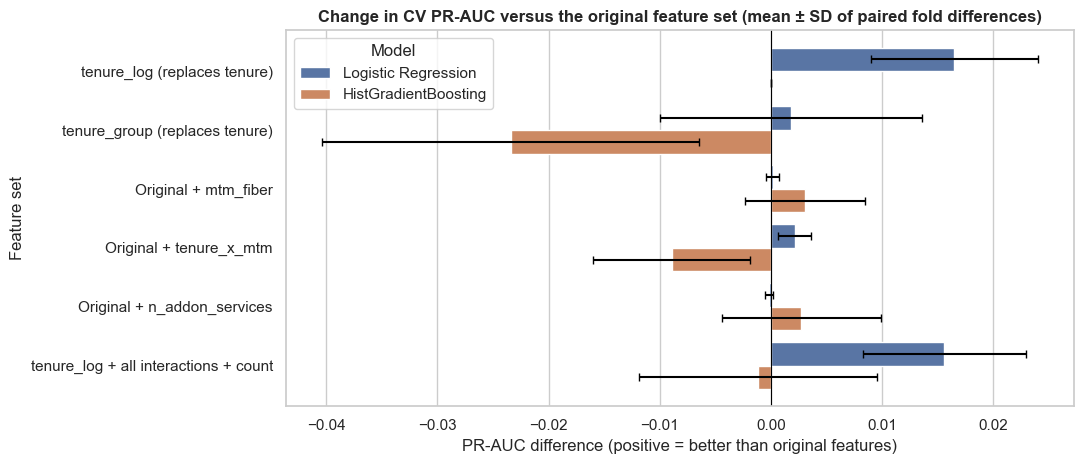

In [35]:
fig, ax = plt.subplots(figsize=(11, 4.8))
plot_fe = fe_results.reset_index()
plot_fe = plot_fe[plot_fe["feature set"] != "Original features"]
sns.barplot(data=plot_fe, y="feature set", x="paired diff vs original", hue="model", errorbar=None, ax=ax)
for container, model_name in zip(ax.containers, FE_MODELS):
    sub = plot_fe[plot_fe["model"] == model_name]
    ax.errorbar([bar.get_width() for bar in container], [bar.get_y() + bar.get_height() / 2 for bar in container],
                xerr=sub["std of paired diff"].to_numpy(), fmt="none", ecolor="black", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Change in CV PR-AUC versus the original feature set (mean ± SD of paired fold differences)")
ax.set_xlabel("PR-AUC difference (positive = better than original features)")
ax.set_ylabel("Feature set")
ax.legend(title="Model")
plt.tight_layout()
save_figure(fig, "00_feature_engineering")
plt.show()

**Interpretation**

- **`tenure_log` is the only clear improvement.** For Logistic Regression it raises CV PR-AUC from 0.650 to **0.667**: +0.0165, better in **5 of 5 folds**, with a paired SD of only 0.0075. The partial-dependence plot in notebook 01 shows why. Predicted risk falls steeply over the first year and flattens afterwards, a shape a straight line in raw months cannot represent.
- **For HistGradientBoosting, `tenure_log` changes nothing** (difference exactly 0.0000). A tree split such as "tenure ≤ 5" is identical to "log(1+tenure) ≤ 1.79", so any monotone transformation leaves tree models unchanged. This confirms the transformation is implemented correctly.
- **Tenure groups do not help.** LR +0.0018 with only 3/5 folds better; HGB −0.023. Binning discards variation within each band, and the boosting model loses the ability to choose its own split points.
- **The interaction and count features add little:**
  - `mtm_fiber`: +0.0002 for LR (it is already almost captured by the separate contract and fiber terms);
  - `n_addon_services`: −0.0002 for LR (exactly collinear with the add-on indicators);
  - `tenure_x_mtm`: +0.0021 for LR, which technically passes the rule (4/5 folds), but the gain is under 0.3 PR-AUC points and it **reduces** HGB performance by 0.009.
- **Combining everything** (+0.0156) is no better than `tenure_log` alone (+0.0165). Once tenure is log-transformed, the other features bring nothing extra.

**Decision (by the pre-specified rule):** three Logistic Regression sets qualify (`tenure_log`, `tenure_x_mtm`, and the combined set). The rule selects the **simplest**: **`tenure_log` replacing `tenure`**. It adds no column, gives the largest gain, and is neutral for the tree models. The same preprocessing is used for all models from here on.

*Limitation:* this decision, like the encoding choice (Section 8.4) and the feature-selection check (Section 10.5), was made with ordinary 5-fold CV on the same folds that are later used as outer folds in the model notebooks (01–06). The nested estimates therefore carry some optimism from these preprocessing choices. Notebook 08, Section 6 quantifies it by repeating all of these choices inside the nested loop.

In [36]:
# Adopt the feature-engineering decision documented above
PREP_CONFIG = {**PREP_CONFIG, "tenure": "log"}
assert PREP_CONFIG == FINAL_PREP_CONFIG, "The decision must match the configuration shared via src/"
print("Final preprocessing configuration:", PREP_CONFIG)
print("Encoded features:", list(make_preprocessor(**PREP_CONFIG).fit(X_train).get_feature_names_out()))

Final preprocessing configuration: {'contract': 'onehot', 'addons': 'binary', 'tenure': 'log'}
Encoded features: ['Dependents_Yes', 'PaperlessBilling_Yes', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'tenure_log', 'MonthlyCharges']


# 10. Feature Selection

The objective is to check whether each feature is **relevant** to churn and whether any feature is **redundant** given the others — not to remove as many features as possible. All analyses use the training set only.

| Method | Applied to | Why it fits the data type |
|---|---|---|
| Chi-square test + **Cramér's V** | Categorical features vs Churn; categorical vs categorical | Tests independence in contingency tables; Cramér's V (0–1) gives the *strength* of association. |
| Mann-Whitney U + rank-biserial correlation | `tenure`, `MonthlyCharges` vs Churn | Non-parametric (no normality assumption — both distributions are clearly non-normal); rank-biserial gives an effect size from −1 to 1. |
| Mutual information | All features vs Churn | Captures any (also non-linear) dependence. |
| Spearman correlation, correlation ratio (η) | numeric–numeric, numeric–categorical redundancy | Detect overlapping information between features. |
| Leave-one-feature-out CV | Logistic Regression and Random Forest | Measures each feature's *marginal* contribution to cross-validated performance given all other features. |

**Statistical caveat.** With almost 4,000 training rows, even very weak associations produce tiny p-values. P-values are therefore reported with a Bonferroni correction for the number of tests, but decisions rely on **effect sizes** and **cross-validated contribution**.

## 10.1 Relevance: Categorical Features vs Churn

In [37]:
cat_tests = []
for col in CATEGORICAL_FEATURES:
    table = pd.crosstab(train_df[col], train_df["Churn"])
    # correction=False: no Yates continuity correction, so chi2 is consistent with Cramér's V
    chi2, p, dof, _ = stats.chi2_contingency(table, correction=False)
    cat_tests.append({"feature": col, "chi2": chi2, "dof": dof, "p_value": p,
                      "cramers_v": association(table.to_numpy(), method="cramer")})
cat_tests = pd.DataFrame(cat_tests).set_index("feature")
n_tests = len(CATEGORICAL_FEATURES) + len(NUMERIC_FEATURES)
cat_tests["p_bonferroni"] = (cat_tests["p_value"] * n_tests).clip(upper=1)
cat_tests = cat_tests.sort_values("cramers_v", ascending=False)
display(cat_tests.style.format({"chi2": "{:.1f}", "p_value": "{:.2e}", "p_bonferroni": "{:.2e}",
                                "cramers_v": "{:.3f}"}))

,chi2,dof,p_value,cramers_v,p_bonferroni
feature,,,,,
Contract,702.1,2,3.42e-153,0.422,3.42e-152
OnlineSecurity,458.3,2,3.10e-100,0.341,3.10e-99
TechSupport,448.0,2,5.20e-98,0.337,5.20e-97
InternetService,415.9,2,4.76e-91,0.325,4.76e-90
OnlineBackup,355.2,2,7.35e-78,0.300,7.35e-77
DeviceProtection,309.8,2,5.27e-68,0.280,5.27e-67
PaperlessBilling,138.7,1,5.07e-32,0.188,5.07e-31
Dependents,121.2,1,3.48e-28,0.175,3.48e-27


## 10.2 Relevance: Numerical Features vs Churn

In [38]:
num_tests = []
for col in NUMERIC_FEATURES:
    churn_vals = train_df.loc[train_df["Churn"] == 1, col]
    stay_vals = train_df.loc[train_df["Churn"] == 0, col]
    u_stat, p = stats.mannwhitneyu(churn_vals, stay_vals, alternative="two-sided")
    rank_biserial = 2 * u_stat / (len(churn_vals) * len(stay_vals)) - 1   # >0: churners tend to have higher values
    r_pb, _ = stats.pointbiserialr(train_df["Churn"], train_df[col])
    num_tests.append({"feature": col, "median (churn)": churn_vals.median(), "median (no churn)": stay_vals.median(),
                      "U": u_stat, "p_value": p, "p_bonferroni": min(p * n_tests, 1.0),
                      "rank_biserial": rank_biserial, "point_biserial_r": r_pb})
display(pd.DataFrame(num_tests).set_index("feature").style.format(
    {"U": "{:.0f}", "p_value": "{:.2e}", "p_bonferroni": "{:.2e}", "rank_biserial": "{:.3f}",
     "point_biserial_r": "{:.3f}", "median (churn)": "{:.2f}", "median (no churn)": "{:.2f}"}))

,median (churn),median (no churn),U,p_value,p_bonferroni,rank_biserial,point_biserial_r
feature,,,,,,,
tenure,9.00,37.00,776076,4.36e-123,4.36e-122,-0.490,-0.359
MonthlyCharges,79.55,64.15,1893284,8.65e-32,8.65e-31,0.244,0.195


## 10.3 Relevance: Mutual Information

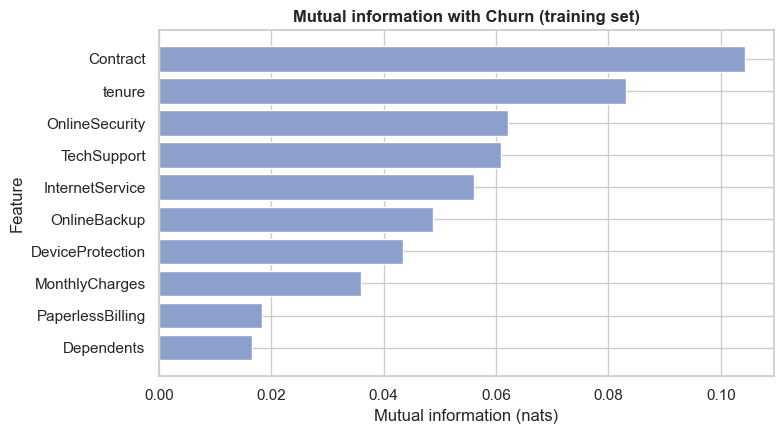

In [39]:
mi_input = X_train.copy()
for col in CATEGORICAL_FEATURES:
    mi_input[col] = mi_input[col].map({v: i for i, v in enumerate(CATEGORY_ORDER[col])})
discrete_mask = [col in CATEGORICAL_FEATURES for col in mi_input.columns]
mi = pd.Series(mutual_info_classif(mi_input, y_train, discrete_features=discrete_mask, random_state=RANDOM_STATE),
               index=mi_input.columns, name="mutual_information").sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(mi.index, mi.values, color="#8DA0CB")
ax.set_title("Mutual information with Churn (training set)")
ax.set_xlabel("Mutual information (nats)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

**Interpretation of relevance**

- **The chi-square statistics use no continuity correction** (`correction=False`), so they are consistent with Cramér's V. For the two binary features this gives slightly larger chi-square values than the Yates-corrected default; conclusions are unaffected.
- **Every feature is significantly associated with churn**, even after Bonferroni correction (all adjusted p-values < 1e-26). As noted above, p-values this small mainly reflect the sample size, so the **effect sizes** carry the information.
- **Categorical features (Cramér's V):**
  - Contract (0.42) has a moderate-to-strong association.
  - OnlineSecurity (0.34), TechSupport (0.34), InternetService (0.33), OnlineBackup (0.30) and DeviceProtection (0.28) are moderate.
  - PaperlessBilling (0.19) and Dependents (0.18) are weak but not negligible.
- **Numerical features (rank-biserial):**
  - tenure **−0.49** is a large effect: churners have much shorter tenure.
  - MonthlyCharges **+0.24** is a small-to-moderate effect: churners pay more.
- **Mutual information** ranks Contract (0.104) and tenure (0.083) highest, followed by OnlineSecurity, TechSupport, InternetService, OnlineBackup, DeviceProtection and MonthlyCharges (0.036–0.062). PaperlessBilling (0.018) and Dependents (0.017) are lowest.
- **The methods agree:** Contract, tenure and the internet/add-on features are the strongest individual signals, and Dependents and PaperlessBilling are the weakest. None of the features is irrelevant.

## 10.4 Redundancy Between Features

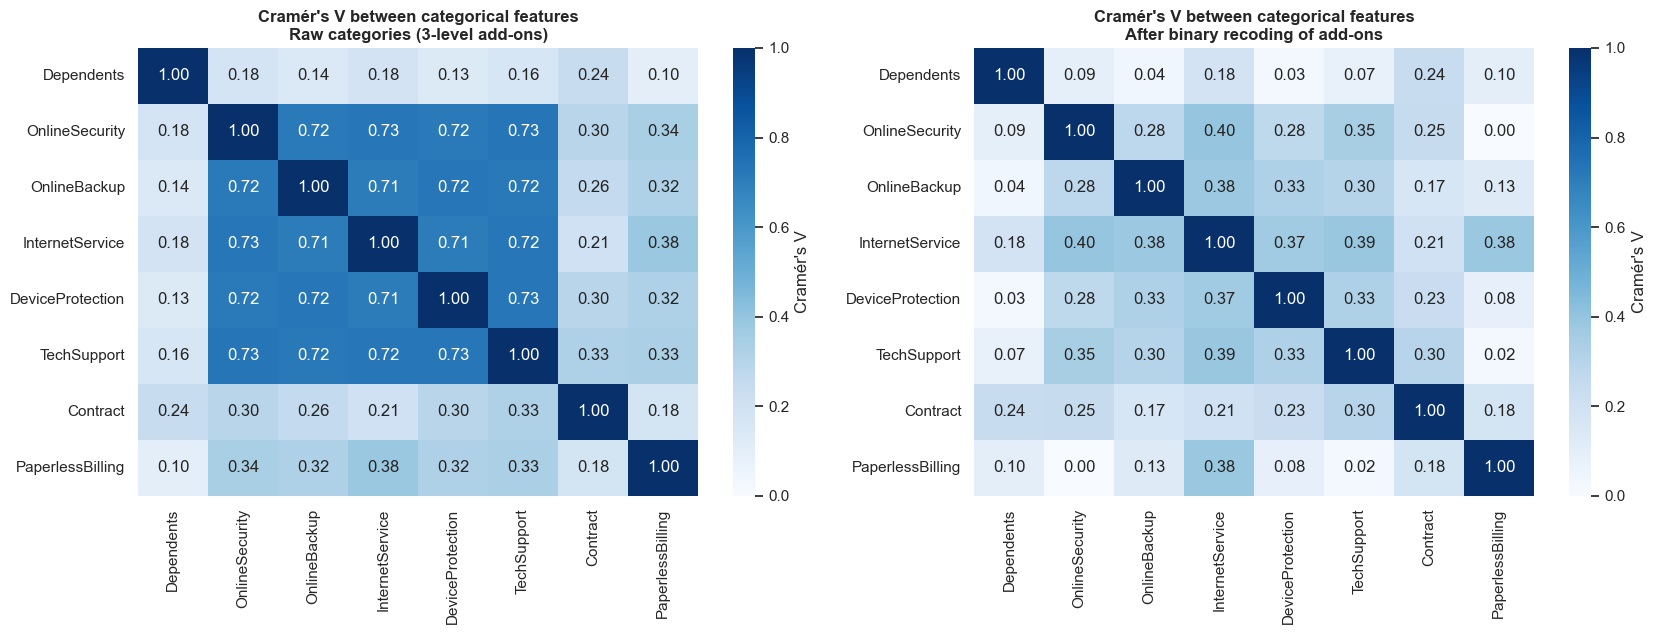

In [40]:
# Cramér's V between all categorical features (raw categories)
cv_matrix = pd.DataFrame(np.eye(len(CATEGORICAL_FEATURES)), index=CATEGORICAL_FEATURES, columns=CATEGORICAL_FEATURES)
for i, a in enumerate(CATEGORICAL_FEATURES):
    for b in CATEGORICAL_FEATURES[i + 1:]:
        v = association(pd.crosstab(X_train[a], X_train[b]).to_numpy(), method="cramer")
        cv_matrix.loc[a, b] = cv_matrix.loc[b, a] = v

# Same matrix after the agreed binary recoding of the add-ons (what the model actually sees)
recoded = X_train[CATEGORICAL_FEATURES].copy()
recoded[ADDON_FEATURES] = encode_addons(recoded[ADDON_FEATURES])
cv_matrix_recoded = cv_matrix.copy()
for i, a in enumerate(CATEGORICAL_FEATURES):
    for b in CATEGORICAL_FEATURES[i + 1:]:
        v = association(pd.crosstab(recoded[a], recoded[b]).to_numpy(), method="cramer")
        cv_matrix_recoded.loc[a, b] = cv_matrix_recoded.loc[b, a] = v

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, mat, title in [(axes[0], cv_matrix, "Raw categories (3-level add-ons)"),
                       (axes[1], cv_matrix_recoded, "After binary recoding of add-ons")]:
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Cramér's V"})
    ax.set_title(f"Cramér's V between categorical features\n{title}")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [41]:
eta_rows = [{"numeric": num, "categorical": cat, "eta": correlation_ratio(X_train[cat], X_train[num])}
            for num in NUMERIC_FEATURES for cat in CATEGORICAL_FEATURES]
eta_table = pd.DataFrame(eta_rows).pivot(index="categorical", columns="numeric", values="eta")
display(eta_table.round(3).style.background_gradient(cmap="Blues", vmin=0, vmax=1)
        .set_caption("Correlation ratio (eta) between numeric and categorical features"))
print(f"Spearman rho (tenure, MonthlyCharges) = {stats.spearmanr(X_train['tenure'], X_train['MonthlyCharges'])[0]:.3f}")

numeric,MonthlyCharges,tenure
categorical,,
Contract,0.070000,0.680000
Dependents,0.112000,0.154000
DeviceProtection,0.789000,0.368000
InternetService,0.905000,0.029000
OnlineBackup,0.776000,0.368000
OnlineSecurity,0.761000,0.333000
PaperlessBilling,0.358000,0.002000
TechSupport,0.765000,0.339000


Spearman rho (tenure, MonthlyCharges) = 0.257


## 10.5 Model-Based Contribution: Leave-One-Feature-Out Cross-Validation

For each feature, the model is retrained without that feature and the drop in cross-validated PR-AUC is measured. A drop close to zero (within fold-to-fold noise) means the remaining features already carry that information. Logistic Regression and Random Forest (default settings, with the Section 9 preprocessing) are used because they represent the two families of models (linear vs tree ensemble). The feature removal happens inside the pipeline, and the same CV folds are used for every run.

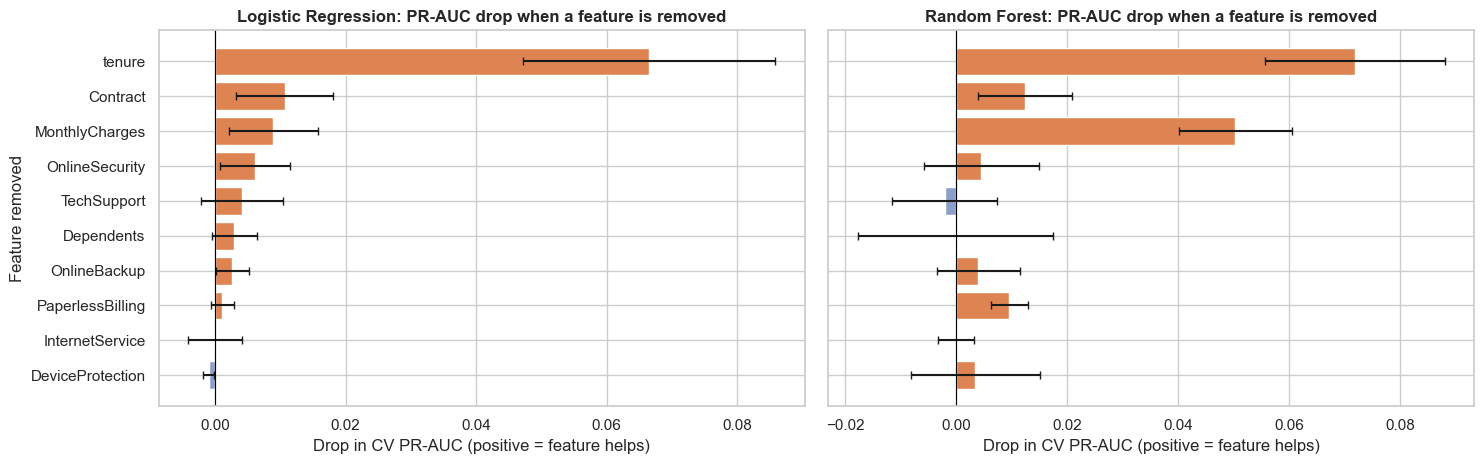

drop (mean)                        drop (std)  \
model            Logistic Regression Random Forest Logistic Regression   
feature removed                                                          
Contract                      0.0107        0.0123              0.0074   
Dependents                    0.0030       -0.0002              0.0035   
DeviceProtection             -0.0009        0.0035              0.0008   
InternetService               0.0000        0.0000              0.0041   
MonthlyCharges                0.0089        0.0503              0.0068   
OnlineBackup                  0.0027        0.0040              0.0025   
OnlineSecurity                0.0061        0.0045              0.0053   
PaperlessBilling              0.0011        0.0095              0.0018   
TechSupport                   0.0041       -0.0021              0.0063   
tenure                        0.0665        0.0718              0.0193   

                               folds where removal hurts                
model            Random Forest       Logistic Regression Random Forest  
feature removed                                                         
Contract                0.0085                    5.0000        5.0000  
Dependents              0.0176                    5.0000        2.0000  
DeviceProtection        0.0116                    0.0000        4.0000  
InternetService         0.0033                    3.0000        3.0000  
MonthlyCharges          0.0102                    5.0000        5.0000  
OnlineBackup            0.0075                    4.0000        4.0000  
OnlineSecurity          0.0103                    4.0000        4.0000  
PaperlessBilling        0.0033                    4.0000        5.0000  
TechSupport             0.0095                    4.0000        2.0000  
tenure                  0.0162                    5.0000        5.0000

In [42]:
LOFO_MODELS = {"Logistic Regression": BASE_MODELS["Logistic Regression"],
               "Random Forest": BASE_MODELS["Random Forest"]}

lofo_rows = []
for model_name, model in LOFO_MODELS.items():
    full = cv_scores(build_pipeline(model, **PREP_CONFIG), X_train, y_train,
                     scoring={"pr_auc": "average_precision"})["test_pr_auc"]
    for feat in FEATURES:
        subset = [f for f in FEATURES if f != feat]
        reduced = cv_scores(build_pipeline(model, features=subset, **PREP_CONFIG), X_train[subset], y_train,
                            scoring={"pr_auc": "average_precision"})["test_pr_auc"]
        delta = full - reduced                      # per-fold drop (paired: same folds)
        lofo_rows.append({"model": model_name, "feature removed": feat, "PR-AUC full": full.mean(),
                          "PR-AUC without": reduced.mean(), "drop (mean)": delta.mean(), "drop (std)": delta.std(),
                          "folds where removal hurts": int((delta > 0).sum())})
lofo = pd.DataFrame(lofo_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
order = lofo[lofo["model"] == "Logistic Regression"].sort_values("drop (mean)")["feature removed"]
for ax, model_name in zip(axes, LOFO_MODELS):
    sub = lofo[lofo["model"] == model_name].set_index("feature removed").loc[order]
    colors = ["#DD8452" if v > 0 else "#8DA0CB" for v in sub["drop (mean)"]]
    ax.barh(sub.index, sub["drop (mean)"], xerr=sub["drop (std)"], color=colors, capsize=3)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{model_name}: PR-AUC drop when a feature is removed")
    ax.set_xlabel("Drop in CV PR-AUC (positive = feature helps)")
axes[0].set_ylabel("Feature removed")
plt.tight_layout()
plt.show()

display(lofo.pivot(index="feature removed", columns="model", values=["drop (mean)", "drop (std)",
                                                                     "folds where removal hurts"]).round(4))

**Redundancy (Section 10.4)**

- **Add-ons vs InternetService.** With the raw 3-level categories, the add-ons and `InternetService` look strongly associated (Cramér's V ≈ 0.71–0.73). That is entirely due to the shared structural "No internet service" level. After the binary recoding used by the models, the associations fall to 0.28–0.40: related, but not redundant.
- **MonthlyCharges vs InternetService:** strongly related (η = 0.905).
- **Tenure vs Contract:** strongly related (η = 0.68).
- **Tenure vs MonthlyCharges:** only weakly correlated (ρ = 0.257).

**Marginal predictive contribution (leave-one-feature-out, with the Section 9 preprocessing)**

- **`tenure` is indispensable.** Removing it costs 0.067 PR-AUC (Logistic Regression) and 0.072 (Random Forest), in 5/5 folds.
- **`MonthlyCharges` and `Contract` help both models consistently.**
  - `MonthlyCharges`: LR −0.009, 5/5 folds; RF −0.050, 5/5.
  - `Contract`: LR −0.011, 5/5; RF −0.012, 5/5.
- **Small but mostly consistent contributors for Logistic Regression:** `OnlineSecurity` (0.006), `TechSupport` (0.004), `Dependents` (0.003, 5/5), `OnlineBackup` (0.003) and `PaperlessBilling` (0.001).
- **`InternetService` shows no marginal contribution in either model** (0.000). Its information is already carried by `MonthlyCharges` (η = 0.905) and by the add-on indicators, which are 0 for customers without internet.
- **`DeviceProtection` is the only feature whose removal slightly *improves* Logistic Regression**, by 0.0009, in all five folds. However, it helps the Random Forest (+0.0035, 4/5), and a 0.1-point PR-AUC change is practically irrelevant.

**How the different kinds of evidence fit together**

| Concept | What it answers | Evidence in this notebook |
|---|---|---|
| Statistical association | Is churn rate different across values of the feature? | All 10 features (chi-square / Mann-Whitney, Bonferroni-adjusted p < 1e-26) |
| Effect size | How strong is the association? | Strongest: Contract (V = 0.42), tenure (rank-biserial −0.49); weakest: Dependents, PaperlessBilling (≈ 0.18) |
| Redundancy | Does another feature carry the same information? | MonthlyCharges ↔ InternetService (η = 0.905); tenure ↔ Contract (η = 0.68) |
| Multicollinearity | Are linear-model coefficients unstable? | VIF 11.2 for MonthlyCharges; ∞ only in the rejected 3-level encoding |
| Predictive usefulness | Does the model perform worse without it? | Clear for tenure, MonthlyCharges, Contract; small or nil for the rest |
| Model-specific importance | How much does a fitted model rely on it? | Permutation importance in notebooks 01–06 |

`InternetService` illustrates the difference well: it is strongly *associated* with churn (V = 0.33), yet *unnecessary* for prediction once `MonthlyCharges` and the add-ons are known.

**Decision: retain all 10 features.**
1. No removal improves cross-validated performance by a meaningful amount. The largest gain (removing `DeviceProtection` from LR) is 0.0009 and is contradicted by the Random Forest.
2. Weak marginal contributions reflect **shared information**, not irrelevance. Removing `InternetService` would not lose information, but would not gain anything either. It would also make the model harder to explain to the CS team, for whom service type is a natural concept.
3. With 10 features and about 3,900 training rows, the overfitting risk from the number of features is low. Regularisation (LR) and leaf-size limits (trees) control complexity, and the L1 option in notebook 01 lets the tuning procedure drop features automatically if that helps.

In [43]:
FINAL_FEATURES = FEATURES.copy()   # decision documented above
print(f"Final feature set ({len(FINAL_FEATURES)} features): {FINAL_FEATURES}")

Final feature set (10 features): ['Dependents', 'tenure', 'OnlineSecurity', 'OnlineBackup', 'InternetService', 'DeviceProtection', 'TechSupport', 'Contract', 'PaperlessBilling', 'MonthlyCharges']


# 11. Summary of Preprocessing Decisions

The decisions below are fixed in `src/data_preprocessing.py` (`FINAL_PREP_CONFIG`) and used unchanged by every modelling notebook.

| Decision | Choice | Evidence (training data) |
|---|---|---|
| Duplicates | 77 exact duplicate rows **kept** | No customer ID; 39 identical profiles with conflicting labels show identical rows can be different customers (Section 5.2) |
| `tenure = 0` | 8 rows **kept** | New two-year customers, a legitimate state (Section 5.6) |
| Outliers | None removed | No values beyond the IQR fences (Section 5.6) |
| Missing values | No imputer | No missing values; the pipeline fails loudly on unexpected data (Section 5.1) |
| Split | Stratified 80/20, `random_state = 34` | 3,944 training / 986 test customers, churn 26.70% / 26.67% (Section 6) |
| Add-on services | Binary: Yes = 1, otherwise 0 | "No internet service" is structural; the 3-level version creates 5 perfectly collinear columns (Sections 5.4, 8.4) |
| `InternetService` | One-hot, reference DSL | Nominal variable (Section 8.1) |
| `Contract` | One-hot, reference Month-to-month | Unequal log-odds steps (p = 0.072); equal CV performance; clearer coefficients (Sections 8.3–8.4) |
| `Dependents`, `PaperlessBilling` | Binary (Yes = 1) | Truly binary (Section 8.1) |
| `tenure` | **$\log(1+\text{tenure})$**, standardised | +0.017 PR-AUC for Logistic Regression in 5/5 folds; no effect on trees (Section 9) |
| `MonthlyCharges` | Standardised | Needed for regularised linear models (Section 8.1) |
| Feature set | All 10 original features | No removal improves CV performance meaningfully (Section 10.5) |

In [44]:
from sklearn import set_config

# The complete preprocessing + model pipeline, shown with Logistic Regression as an example estimator
set_config(display="text")
example_pipeline = build_pipeline(LogisticRegression(max_iter=5000), **FINAL_PREP_CONFIG)
print(example_pipeline)
print("\nEncoded features produced from the 10 original columns:")
print(list(make_preprocessor(**FINAL_PREP_CONFIG).fit(X_train).get_feature_names_out()))

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('binary',
                                                  OneHotEncoder(categories=[['No',
                                                                             'Yes'],
                                                                            ['No',
                                                                             'Yes']],
                                                                drop='first',
                                                                sparse_output=False),
                                                  ['Dependents',
                                                   'PaperlessBilling']),
                                                 ('addons',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function encode_addons at 0x0000

**What the modelling notebooks inherit.**
- Every model notebook (01–06) and the class-imbalance notebook (07) loads the same validated data, recreates the same split with `split_train_test`, and builds its pipeline with `build_pipeline(model, **FINAL_PREP_CONFIG)`.
- Preprocessing is therefore identical across models and refitted inside every fold.
- The test set created in Section 6 stays untouched until notebook 09.
- **Limitation:** the choices in this notebook (encoding, `tenure_log`, keeping all 10 features) were made with ordinary 5-fold CV on the training set, using the same folds that later serve as outer folds. They were not re-selected inside every outer fold. Notebook 08, Section 6 repeats them inside the nested loop to measure the resulting optimism.

The next question is which algorithm turns these 12 encoded features into the best-ranked churn probabilities. Notebook 01 starts with the simplest candidate, Logistic Regression.